# РОЗДІЛ 4. ЧИСЛОВІ ЕКСПЕРИМЕНТИ ТА АНАЛІЗ РЕЗУЛЬТАТІВ ІДЕНТИФІКАЦІЇ ПАРАМЕТРІВ СТРУНИ

У цьому розділі реалізовано прямий чисельний розрахунок усіх таблиць (**Таблиці 4.1–4.8**) та графіків (**Рисунки 4.1–4.9**) із розв’язання оберненої задачі ідентифікації параметрів струни $\boldsymbol{\theta} = [a, l, A]^T$ на синтетичній вибірці обсягом $M = 100\,000$ реалізацій ($M_{\mathrm{train}} = 80\,000$, $M_{\mathrm{test}} = 20\,000$) для базової сітки спостережень $P = 49$ ($7 \times 7$):
- **Підрозділ 4.1.** Спектральний аналіз коваріаційного оператора хвильового поля (**Таблиця 4.1**, **Рисунок 4.1**).
- **Підрозділ 4.2.** Дослідження та вибір оптимальної розмірності латентного простору $K$ (**Таблиця 4.2**, **Рисунок 4.2**).
- **Підрозділ 4.3.** Порівняльний аналіз моделей машинного навчання (`MLP`, `Extra Trees`, `k-NN`) при $K = 4$ та вимірювання їхньої швидкодії (**Таблиці 4.3, 4.4**, **Рисунки 4.3, 4.4, 4.5**).
- **Підрозділ 4.4.** Дослідження робастності моделей до рівня мультиплікативних завад $\delta \in [0{,}1\%;\; 10{,}0\%]$ (**Таблиця 4.5**, **Рисунок 4.6**).
- **Підрозділ 4.5.** Дослідження впливу кількості датчиків та конфігурації сітки $P \in \{25, 36, 49, 64, 81\}$ (**Таблиця 4.6**, **Рисунок 4.7**).
- **Підрозділ 4.6.** Двоетапна (каскадна) схема ідентифікації `Cascade MLP` (**Таблиця 4.7**, **Рисунок 4.8**).
- **Підрозділ 4.7.** Верифікація моделей у розширеному діапазоні фазової швидкості $a \in [1{,}0;\; 30{,}0]$ м/с (**Таблиця 4.8**, **Рисунок 4.9**).

## 4.1–4.2. Спектральний аналіз коваріаційного оператора та вибір розмірності латентного базису $K$ (**Таблиці 4.1, 4.2**, **Рисунки 4.1, 4.2**)

 ТАБЛИЦЯ 4.1 – Спектральний розподіл дисперсії та фізична інтерпретація головних компонентів (P = 49, delta = 1,0%) 
 Головна компонента  | Власне значення λ_k | Частка дисперсії | Кумулятивна частка | Фізичний зміст моди у хвильовому полі
----------------------------------------------------------------------------------------------------------------------
        ГК 1         |     1,576·10^-1     |      98,36%      |       98,36%       | Основна стояча хвиля: амплітудний масштаб та початковий відгин (A)
        ГК 2         |     2,159·10^-3     |      1,35%       |       99,71%       | Динаміка фазового зсуву хвилі в часі: фазова швидкість (a)
        ГК 3         |     2,656·10^-4     |      0,17%       |       99,87%       | Просторовий градієнт форми хвилі: робоча довжина прольоту (l)
        ГК 4         |     6,655·10^-6     |      0,004%      |       99,88%       | 3-я просторова гармоніка (n=3): корекція співвідношення a/l
 ГК 5–49 (сумарно)   |    < 6,61·10^-6     |     < 0,

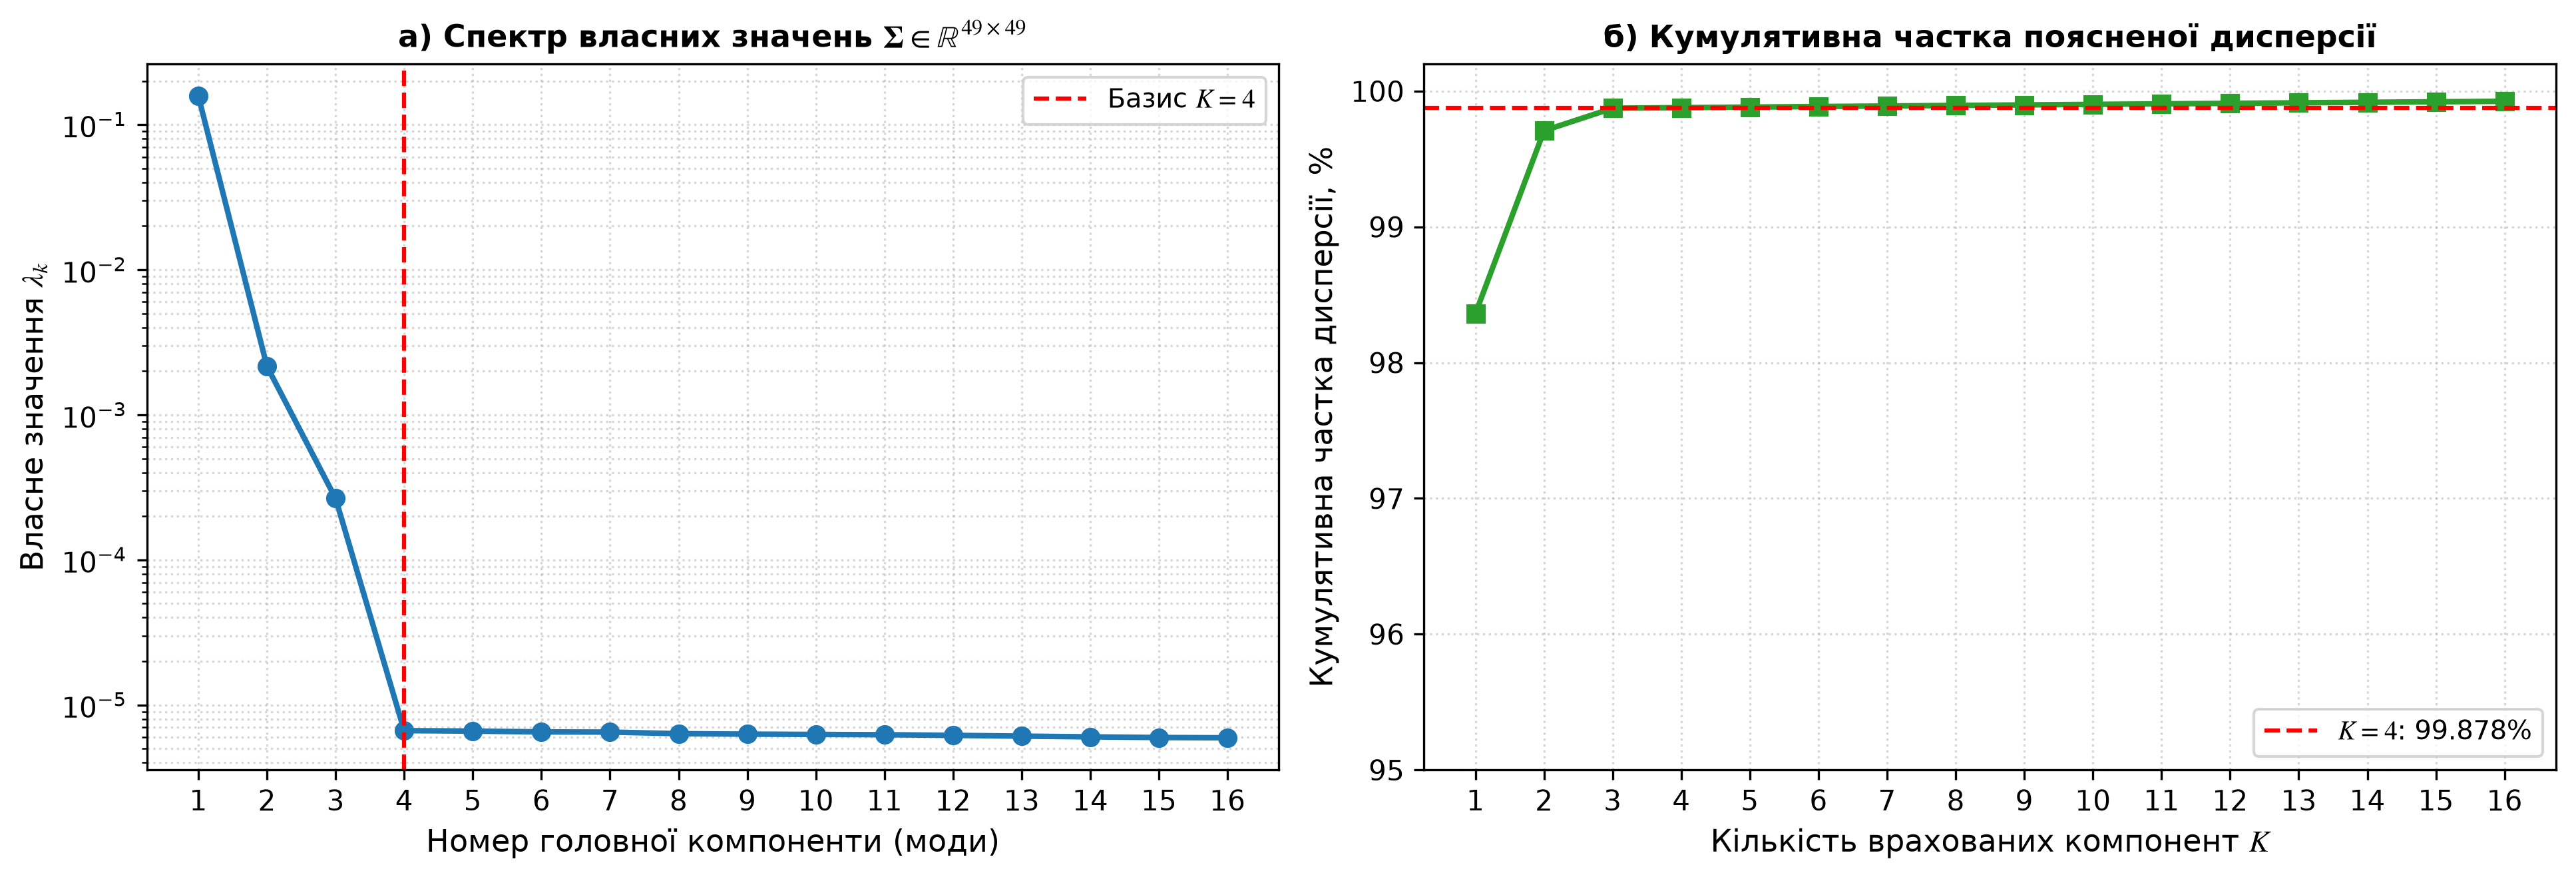

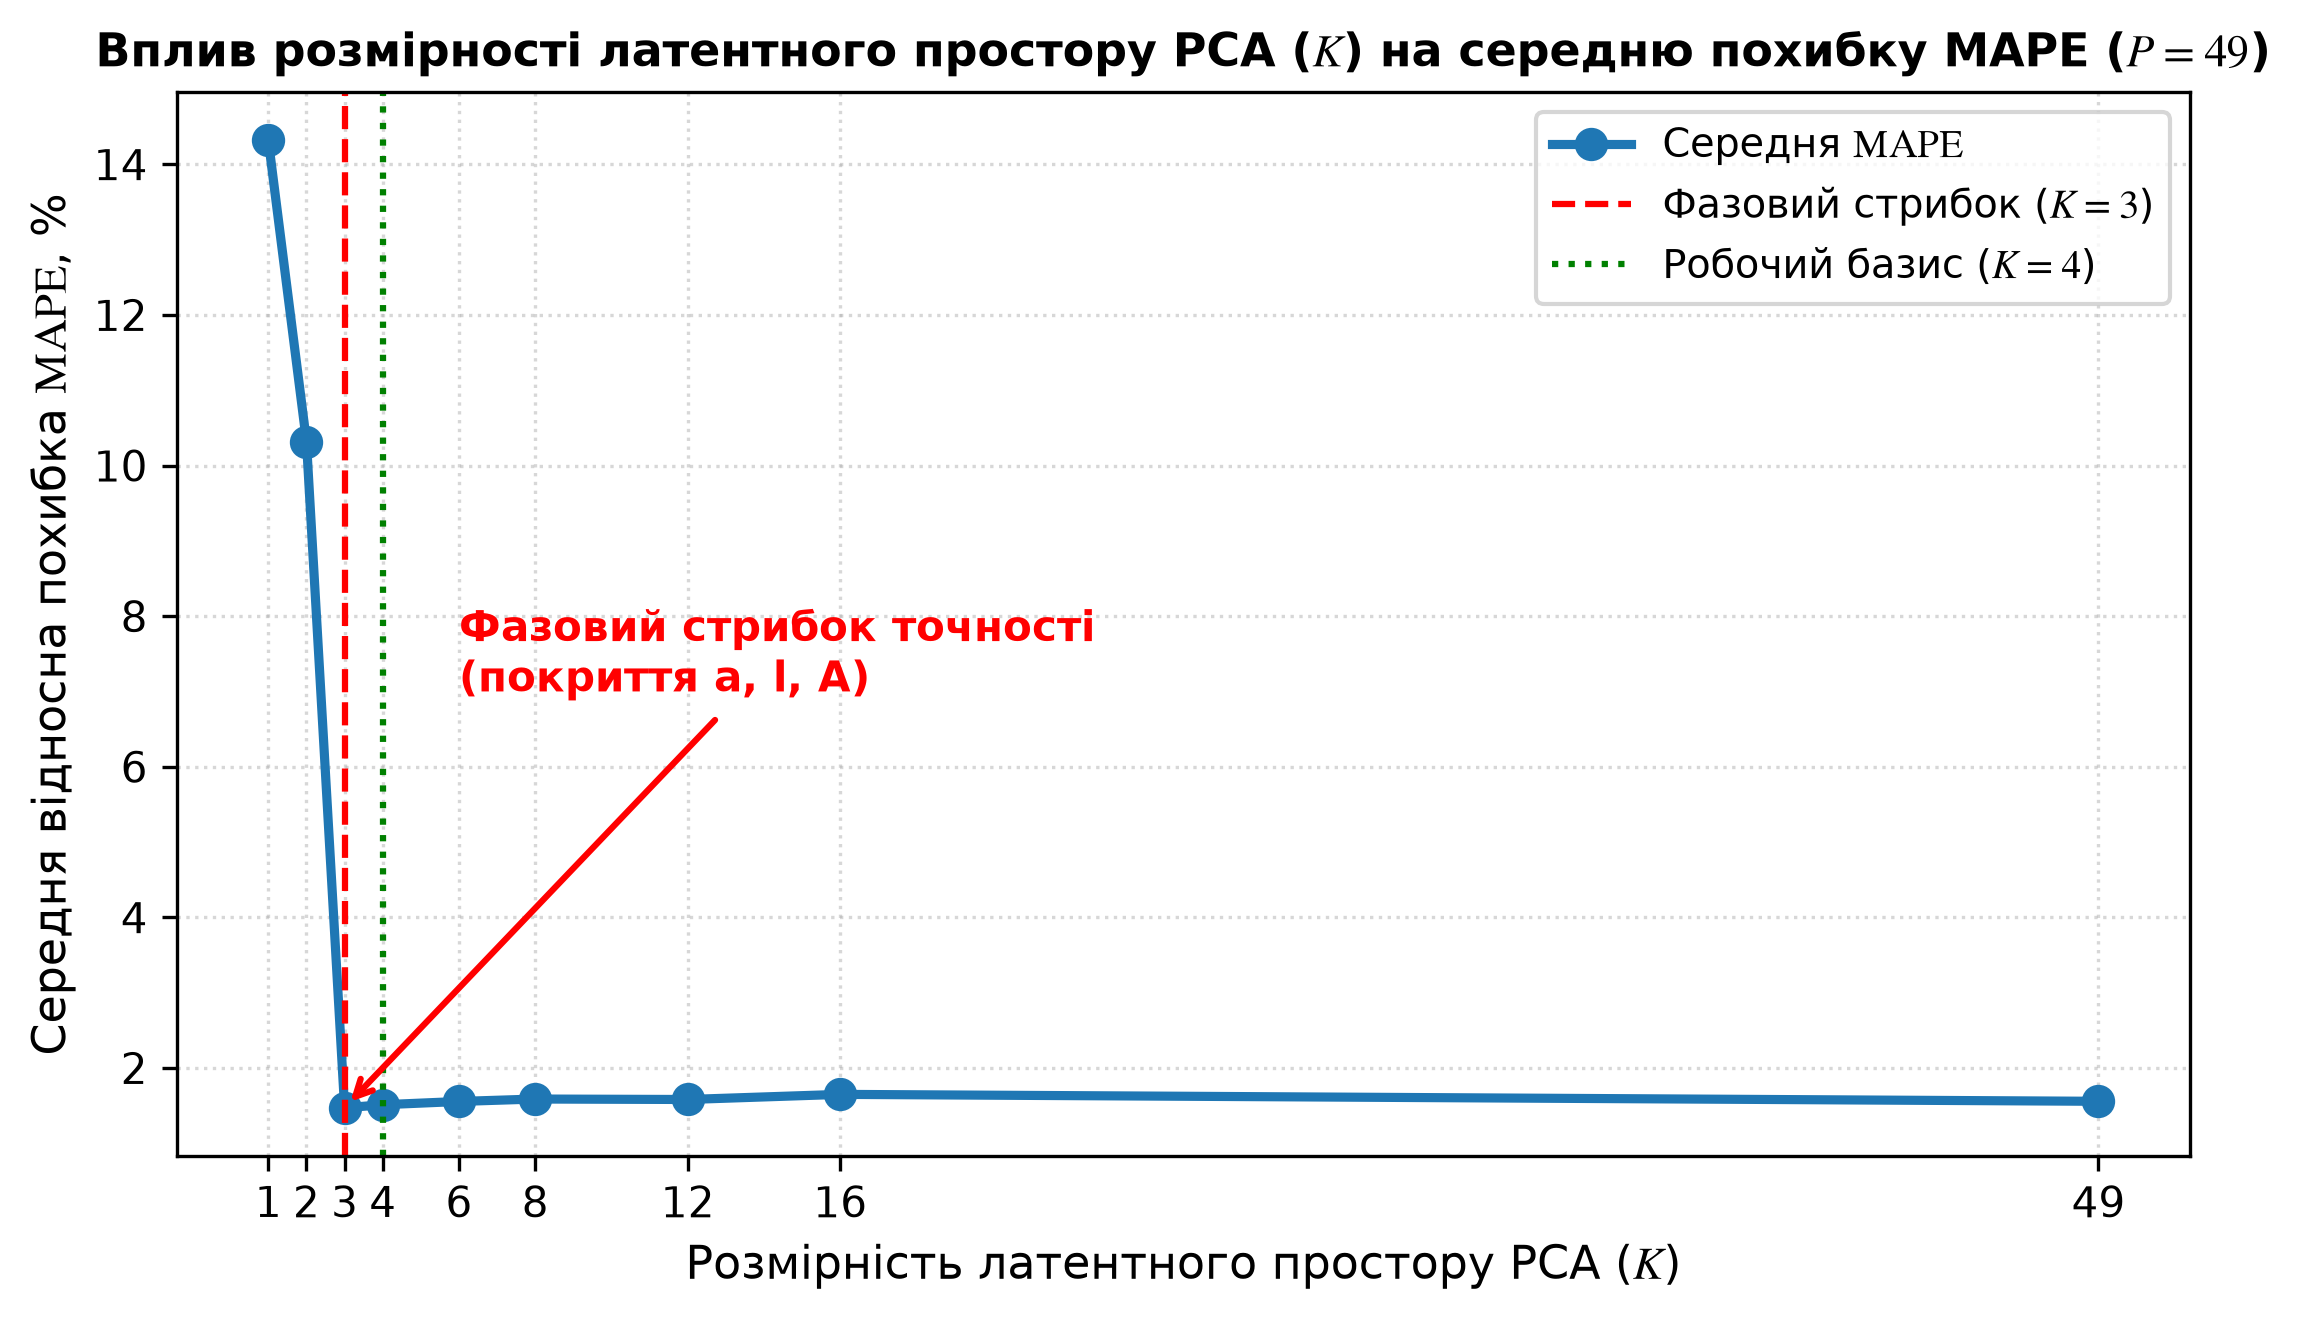

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score

BOUNDS = np.array([[1.0, 3.2], [0.8, 1.2], [0.8, 1.2]], dtype=np.float64)
X_MIN, X_MAX = 0.10, 0.70
T_MIN, T_MAX = 0.01, 0.05
N_X_BASE, N_T_BASE = 7, 7
P_BASE = N_X_BASE * N_T_BASE

XS_BASE = np.linspace(X_MIN, X_MAX, N_X_BASE)
TS_BASE = np.linspace(T_MIN, T_MAX, N_T_BASE)
XG_BASE, TG_BASE = np.meshgrid(XS_BASE, TS_BASE)
X_FLAT_BASE, T_FLAT_BASE = XG_BASE.ravel(), TG_BASE.ravel()

def fmt_sci_ua(val, decimals=3):
    if val == 0:
        return "0,00"
    exp = int(np.floor(np.log10(abs(val))))
    mant = val / (10.0 ** exp)
    return f"{mant:.{decimals}f}".replace(".", ",") + f"·10^{exp}"

def lhs_sample(n_samples, bounds, seed=42):
    rng = np.random.default_rng(seed)
    dim = bounds.shape[0]
    res = np.zeros((n_samples, dim), dtype=np.float64)
    for j in range(dim):
        u = rng.uniform(0.0, 1.0, size=n_samples)
        strat = (rng.permutation(n_samples) + u) / float(n_samples)
        res[:, j] = bounds[j, 0] + strat * (bounds[j, 1] - bounds[j, 0])
    return res

def eval_U_field(a, l, A, x_pts, t_pts, K=41):
    xf, tf = x_pts[None, :], t_pts[None, :]
    U = np.zeros((a.shape[0], x_pts.shape[0]), dtype=np.float64)
    for n in range(K):
        m = 2.0 * n + 1.0
        coeff = (8.0 * A * (l ** 2)) / ((np.pi ** 3) * (m ** 3))
        U += coeff * np.sin(m * np.pi * xf / l) * np.cos(m * np.pi * a * tf / l)
    return U

def calc_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_pred - y_true), axis=0)
    rmse = np.sqrt(np.mean((y_pred - y_true) ** 2, axis=0))
    mape = np.mean(np.abs((y_pred - y_true) / y_true), axis=0) * 100.0
    r2 = r2_score(y_true, y_pred, multioutput="raw_values")
    return mae, rmse, mape, r2

# 1. Генерація синтетичної вибірки LHS (M = 100 000: 80 000 train / 20 000 test)
M_SAMPLES = 100000
N_TRAIN = 80000
N_TEST = 20000

Y_all = lhs_sample(M_SAMPLES, BOUNDS, seed=42)
U_clean_base = eval_U_field(Y_all[:, 0:1], Y_all[:, 1:2], Y_all[:, 2:3], X_FLAT_BASE, T_FLAT_BASE, K=41)
U_noisy_base = U_clean_base + np.random.default_rng(42).normal(0.0, 0.01 * np.abs(U_clean_base))

X_tr, X_te = U_noisy_base[:N_TRAIN], U_noisy_base[N_TRAIN:]
Y_tr, Y_te = Y_all[:N_TRAIN], Y_all[N_TRAIN:]

# 2. Прямий спектральний розклад коваріаційної матриці (Таблиця 4.1)
mean_X = np.mean(X_tr, axis=0)
cov_X = np.cov(X_tr - mean_X, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov_X)
idx_sort = np.argsort(eigvals)[::-1]
eigvals = np.maximum(eigvals[idx_sort], 0.0)
eigvecs = eigvecs[:, idx_sort]

tot_var = np.sum(eigvals)
var_ratios = (eigvals / tot_var) * 100.0
cum_ratios = np.cumsum(var_ratios)

mode_meanings = [
    "Основна стояча хвиля: амплітудний масштаб та початковий відгин (A)",
    "Динаміка фазового зсуву хвилі в часі: фазова швидкість (a)",
    "Просторовий градієнт форми хвилі: робоча довжина прольоту (l)",
    "3-я просторова гармоніка (n=3): корекція співвідношення a/l",
]
TABLE_4_1 = []
for k_i in range(4):
    lam_str = fmt_sci_ua(eigvals[k_i], 3)
    var_fmt = f"{var_ratios[k_i]:.2f}%".replace(".", ",") if var_ratios[k_i] >= 0.01 else f"{var_ratios[k_i]:.3f}%".replace(".", ",")
    cum_fmt = f"{cum_ratios[k_i]:.2f}%".replace(".", ",")
    TABLE_4_1.append([f"ГК {k_i + 1}", lam_str, var_fmt, cum_fmt, mode_meanings[k_i]])

rem_var = float(np.sum(var_ratios[4:]))
TABLE_4_1.append([
    "ГК 5–49 (сумарно)",
    f"< {fmt_sci_ua(eigvals[4], 2)}",
    f"< {rem_var:.2f}%".replace(".", ","),
    "100,00%",
    "Високочастотні залишкові завади та некорельований шум вимірювань",
])

print("=" * 118)
print(" ТАБЛИЦЯ 4.1 – Спектральний розподіл дисперсії та фізична інтерпретація головних компонентів (P = 49, delta = 1,0%) ")
print("=" * 118)
print(f"{'Головна компонента':^20} | {'Власне значення λ_k':^19} | {'Частка дисперсії':^16} | {'Кумулятивна частка':^18} | {'Фізичний зміст моди у хвильовому полі'}")
print("-" * 118)
for row in TABLE_4_1:
    print(f"{row[0]:^20} | {row[1]:^19} | {row[2]:^16} | {row[3]:^18} | {row[4]}")
print("=" * 118)

# 3. Прямий розрахунок залежності похибки від розмірності K (Таблиця 4.2)
k_sweep = [1, 2, 3, 4, 6, 8, 12, 16, 49]
sub_k_tr, sub_k_te = 15000, 4000
scY_k = StandardScaler().fit(Y_tr[:sub_k_tr])
Y_tr_k_s = scY_k.transform(Y_tr[:sub_k_tr])

TABLE_4_2 = []
k_mape_means = []
for k in k_sweep:
    Z_k_tr = (X_tr[:sub_k_tr] - mean_X) @ eigvecs[:, :k]
    Z_k_te = (X_te[:sub_k_te] - mean_X) @ eigvecs[:, :k]
    scZ_k = StandardScaler().fit(Z_k_tr)

    mdl_k = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=30, batch_size=256, random_state=42)
    mdl_k.fit(scZ_k.transform(Z_k_tr), Y_tr_k_s)
    pred_k = scY_k.inverse_transform(mdl_k.predict(scZ_k.transform(Z_k_te)))

    m_k = calc_metrics(Y_te[:sub_k_te], pred_k)
    err_pca = float(np.sum(eigvals[k:]) / tot_var)
    comp_pct = (1.0 - k / float(P_BASE)) * 100.0
    mape_mean_k = float(np.mean(m_k[2]))
    r2_mean_k = float(np.mean(m_k[3]))
    k_mape_means.append(mape_mean_k)

    loss_str = "0,00" if k == P_BASE else fmt_sci_ua(err_pca, 2)
    TABLE_4_2.append([
        str(k),
        f"{cum_ratios[k - 1]:.2f}%".replace(".", ","),
        loss_str,
        f"{m_k[2][0]:.2f}%".replace(".", ","),
        f"{m_k[2][1]:.2f}%".replace(".", ","),
        f"{m_k[2][2]:.2f}%".replace(".", ","),
        f"{mape_mean_k:.2f}%".replace(".", ","),
        f"{r2_mean_k:.4f}".replace(".", ","),
        f"{comp_pct:.1f}%".replace(".", ","),
    ])

print("\n" + "=" * 118)
print(" ТАБЛИЦЯ 4.2 – Залежність похибки ідентифікації (модель MLP) та інформативності базису від кількості ГК K (P = 49) ")
print("=" * 118)
print(f"{'K':^4} | {'Дисперсія':^10} | {'Втрата енергії':^14} | {'MAPE a':^9} | {'MAPE l':^9} | {'MAPE A':^9} | {'Сер. MAPE':^10} | {'Сер. R^2':^9} | {'Стиснення':^10}")
print("-" * 118)
for r in TABLE_4_2:
    print(f"{r[0]:^4} | {r[1]:^10} | {r[2]:^14} | {r[3]:^9} | {r[4]:^9} | {r[5]:^9} | {r[6]:^10} | {r[7]:^9} | {r[8]:^10}")
print("=" * 118)

# Рисунок 4.1: Спектр власних значень та кумулятивна частка дисперсії
modes = np.arange(1, 17)
fig4_1, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.0, 4.5), dpi=150)
ax1.semilogy(modes, eigvals[:16], "o-", color="#1f77b4", lw=2.0, ms=6)
ax1.axvline(4, color="red", ls="--", lw=1.5, label="Базис $K = 4$")
ax1.set_xlabel("Номер головної компоненти (моди)", fontsize=11)
ax1.set_ylabel(r"Власне значення $\lambda_k$", fontsize=11)
ax1.set_title(r"а) Спектр власних значень $\boldsymbol{\Sigma} \in \mathbb{R}^{49 \times 49}$", fontsize=11, fontweight="bold")
ax1.set_xticks(modes)
ax1.grid(True, which="both", linestyle=":", alpha=0.5)
ax1.legend(fontsize=9.5)

ax2.plot(modes, cum_ratios[:16], "s-", color="#2ca02c", lw=2.0, ms=6)
ax2.axhline(cum_ratios[3], color="red", ls="--", lw=1.5, label=f"$K=4$: {cum_ratios[3]:.3f}%")
ax2.set_xlabel("Кількість врахованих компонент $K$", fontsize=11)
ax2.set_ylabel("Кумулятивна частка дисперсії, %", fontsize=11)
ax2.set_title("б) Кумулятивна частка поясненої дисперсії", fontsize=11, fontweight="bold")
ax2.set_xticks(modes)
ax2.set_ylim(95.0, 100.2)
ax2.grid(True, linestyle=":", alpha=0.5)
ax2.legend(loc="lower right", fontsize=9.5)
plt.tight_layout()
plt.show()

# Рисунок 4.2: Вплив розмірності K на середню похибку MAPE
fig4_2, ax = plt.subplots(figsize=(7.5, 4.5), dpi=150)
ax.plot(k_sweep, k_mape_means, "o-", color="#1f77b4", lw=2.2, ms=7, label=r"Середня $\mathrm{MAPE}$")
ax.axvline(3, color="red", ls="--", lw=1.5, label="Фазовий стрибок ($K = 3$)")
ax.axvline(4, color="green", ls=":", lw=1.5, label="Робочий базис ($K = 4$)")
ax.annotate("Фазовий стрибок точності\n(покриття a, l, A)", xy=(3, k_mape_means[2]), xytext=(6, 7.0),
            arrowprops=dict(arrowstyle="->", lw=1.5, color="red"), fontsize=10, fontweight="bold", color="red")
ax.set_xlabel("Розмірність латентного простору PCA ($K$)", fontsize=11)
ax.set_ylabel(r"Середня відносна похибка $\mathrm{MAPE}$, %", fontsize=11)
ax.set_title("Вплив розмірності латентного простору PCA ($K$) на середню похибку MAPE ($P = 49$)", fontsize=11, fontweight="bold")
ax.set_xticks(k_sweep)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(fontsize=9.5)
plt.tight_layout()
plt.show()

## 4.3. Порівняльний аналіз моделей машинного навчання на латентному PCA-просторі ($K = 4$) та вимірювання швидкодії (**Таблиці 4.3, 4.4**, **Рисунки 4.3–4.5**)

 ТАБЛИЦЯ 4.3 – Порівняльний аналіз точності регресійних моделей на тестовій вибірці (20 000 прикладів) 
     Модель      |   Параметр   |    MAE     |    RMSE    |  MAPE, %   |    R^2     |  Сер. MAPE, % 
---------------------------------------------------------------------------------------------------------
      MLP        |    a, м/с    |   0,0657   |   0,0875   |   3,78%    |   0,9809   |     1,50%     
      MLP        |     l, м     |   0,0025   |   0,0032   |   0,25%    |   0,9992   |     1,50%     
      MLP        |   A, м^-1    |   0,0046   |   0,0059   |   0,47%    |   0,9974   |     1,50%     
  Extra Trees    |    a, м/с    |   0,0654   |   0,0874   |   3,74%    |   0,9810   |     1,59%     
  Extra Trees    |     l, м     |   0,0046   |   0,0065   |   0,46%    |   0,9969   |     1,59%     
  Extra Trees    |   A, м^-1    |   0,0056   |   0,0073   |   0,56%    |   0,9960   |     1,59%     
  k-NN (k = 7)   |    a, м/с    |   0,0759   |   0,0999   |   4,37%    |   0,9751  

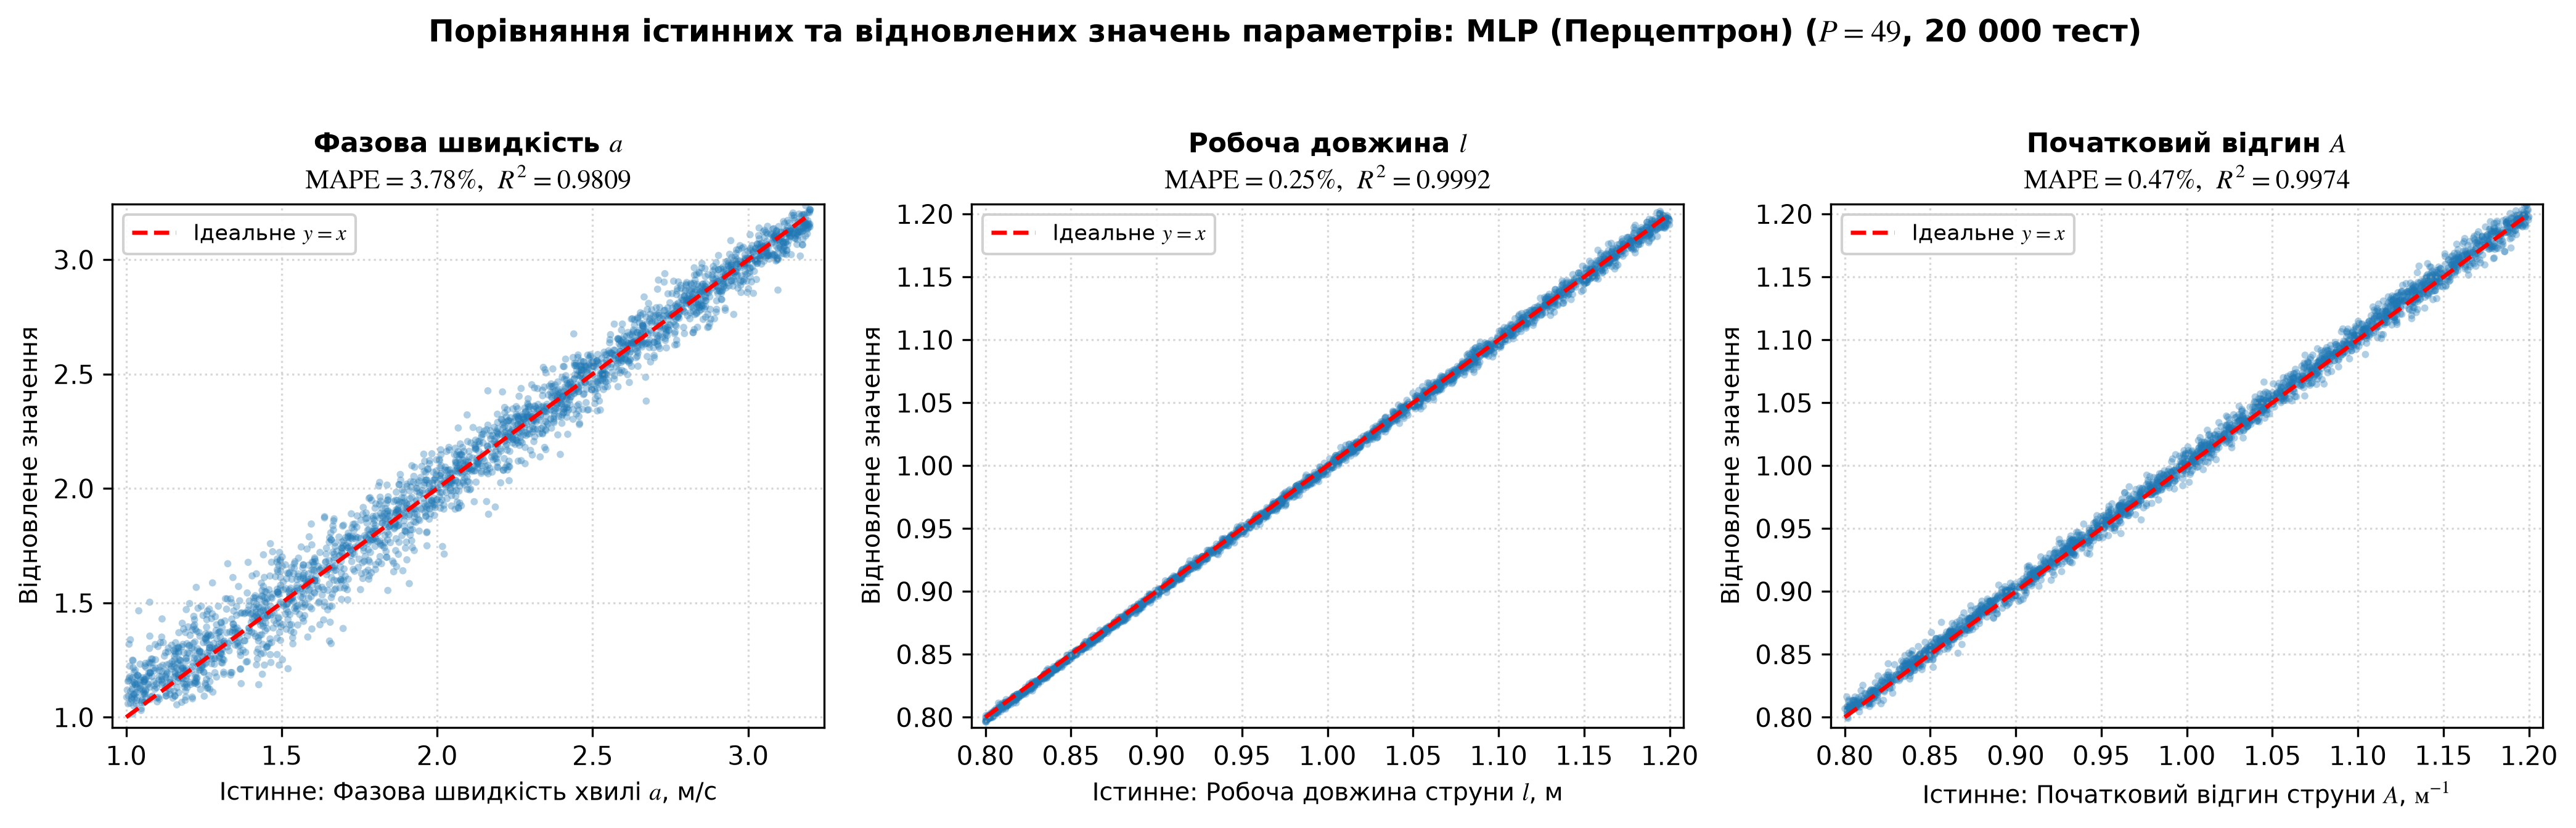

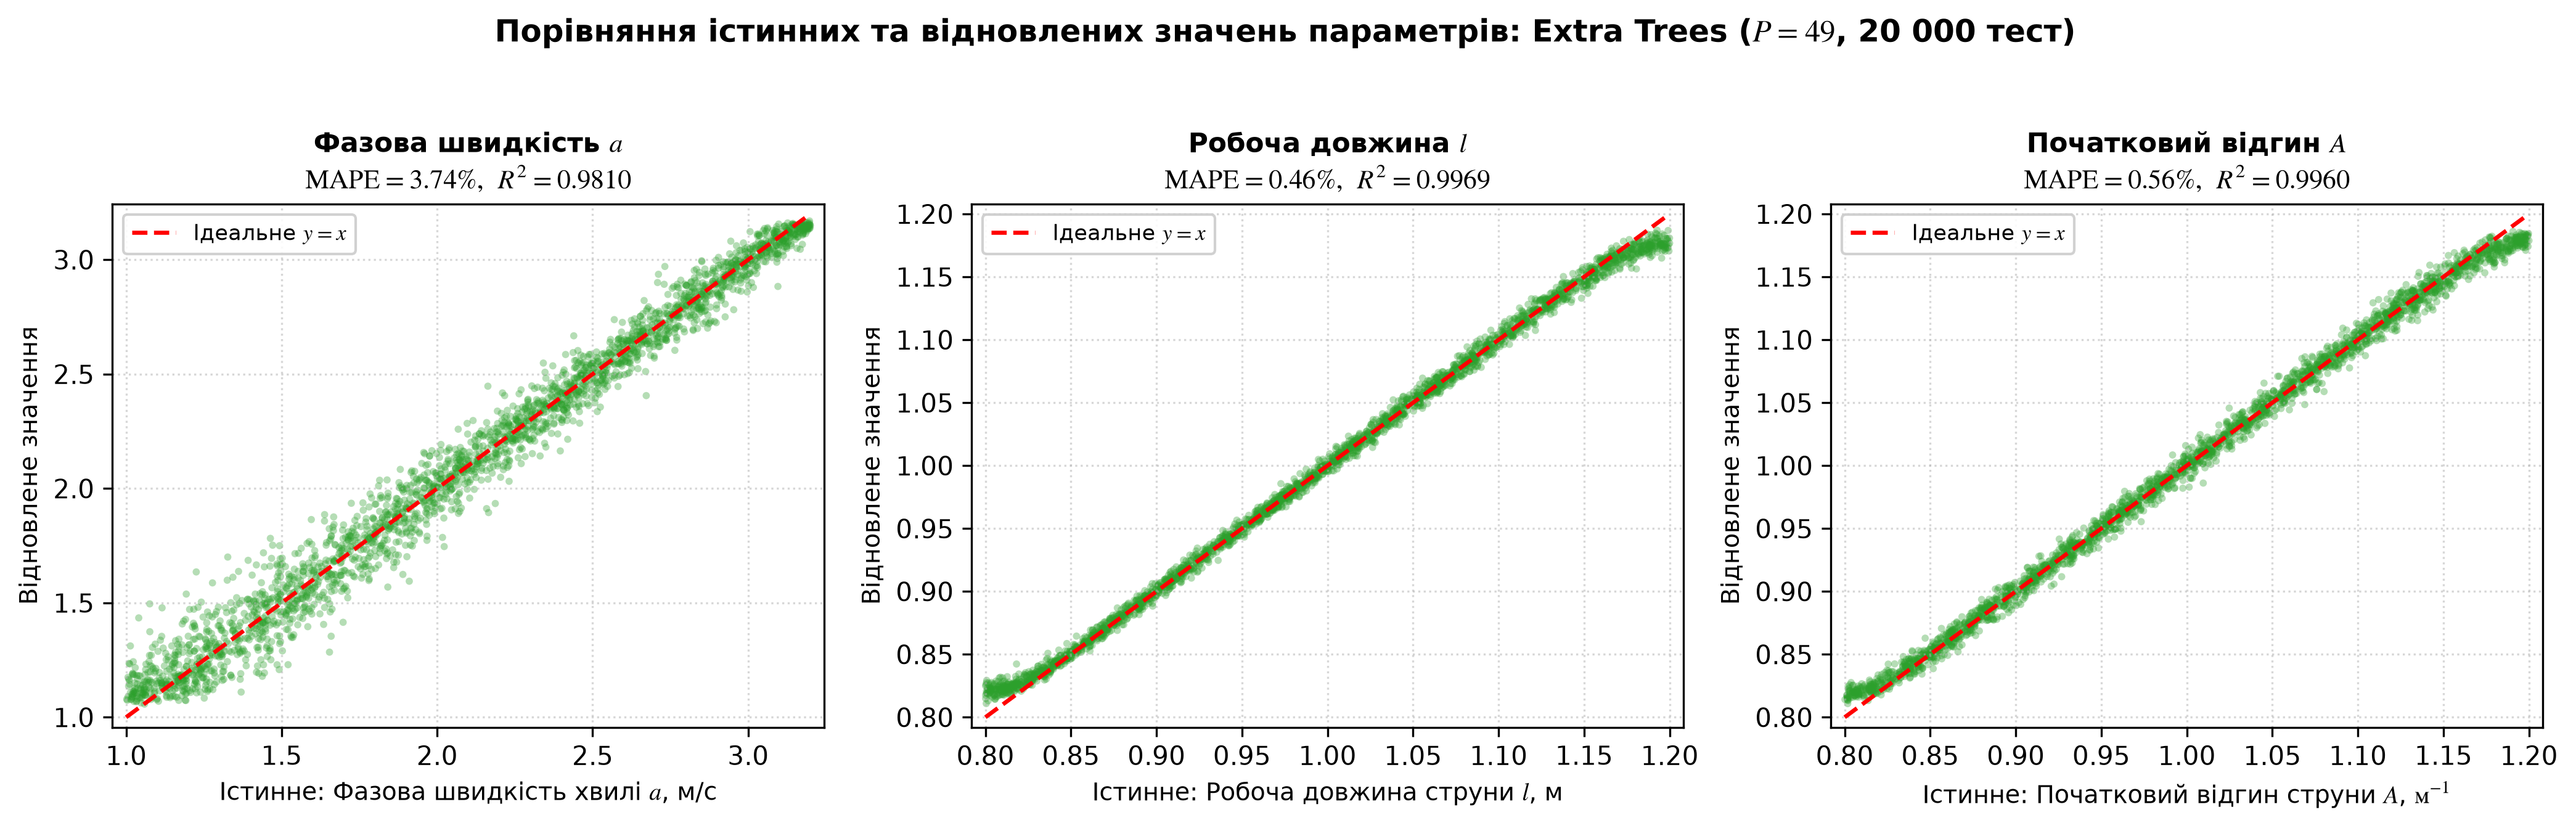

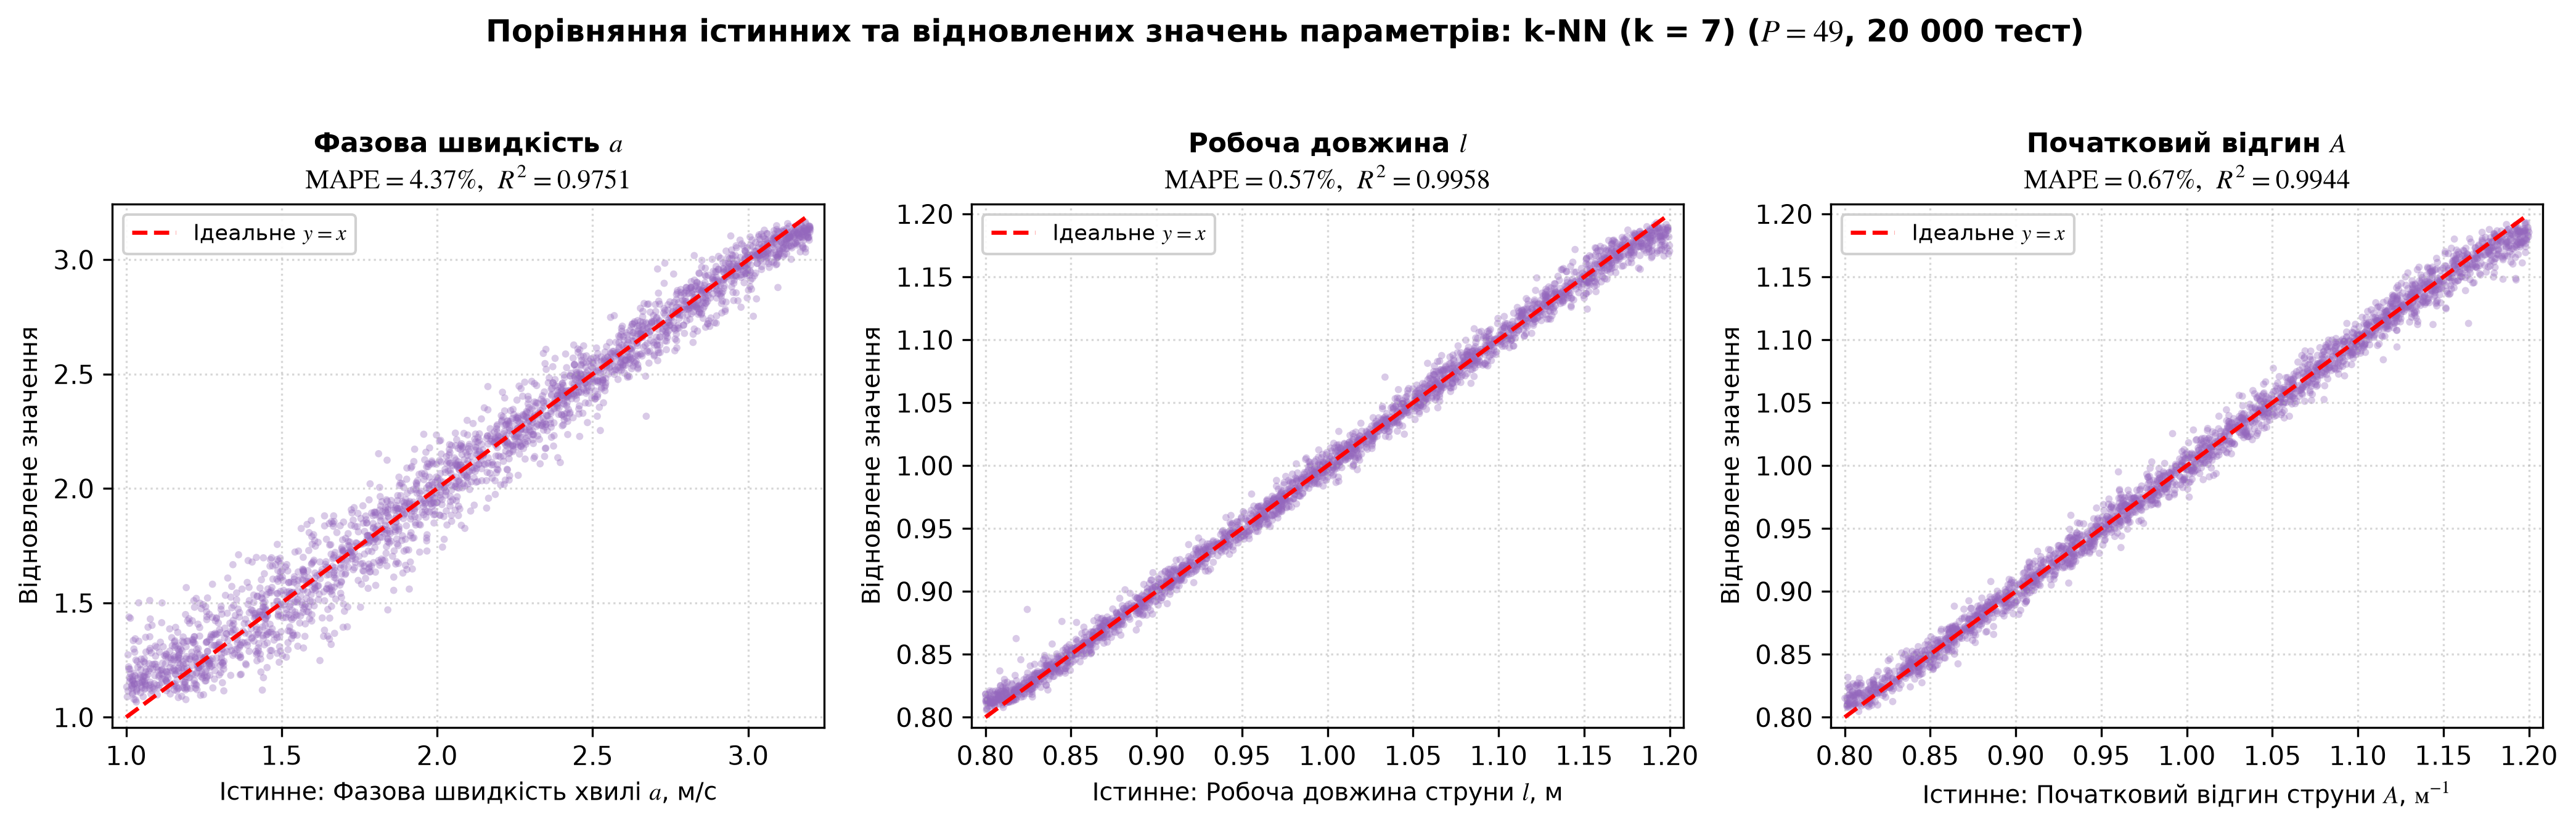

In [2]:
# Проєктування у 4-вимірний латентний PCA-простір (K = 4)
Z_tr = (X_tr - mean_X) @ eigvecs[:, :4]
Z_te = (X_te - mean_X) @ eigvecs[:, :4]

scZ = StandardScaler().fit(Z_tr)
scY = StandardScaler().fit(Y_tr)
Z_tr_s = scZ.transform(Z_tr)
Z_te_s = scZ.transform(Z_te)
Y_tr_s = scY.transform(Y_tr)

# 1) Навчання та оцінювання MLP (Багатошаровий перцептрон)
t0 = time.perf_counter()
mlp = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    max_iter=45,
    batch_size=512,
    learning_rate_init=0.003,
    random_state=42,
)
mlp.fit(Z_tr_s, Y_tr_s)
train_time_mlp = time.perf_counter() - t0

t0 = time.perf_counter()
pred_mlp = scY.inverse_transform(mlp.predict(Z_te_s))
infer_time_mlp = ((time.perf_counter() - t0) / N_TEST) * 1e6
m_mlp = calc_metrics(Y_te, pred_mlp)

# 2) Навчання та оцінювання Extra Trees (Ансамбль екстремально рандомізованих дерев)
t0 = time.perf_counter()
et = ExtraTreesRegressor(n_estimators=40, max_depth=16, min_samples_leaf=4, random_state=42, n_jobs=1)
et.fit(Z_tr[:40000], Y_tr[:40000])
train_time_et = time.perf_counter() - t0

t0 = time.perf_counter()
pred_et = et.predict(Z_te)
infer_time_et = ((time.perf_counter() - t0) / N_TEST) * 1e6
m_et = calc_metrics(Y_te, pred_et)

# 3) Навчання та оцінювання k-NN (k = 7 сусідів)
t0 = time.perf_counter()
knn = KNeighborsRegressor(n_neighbors=7, weights="distance", n_jobs=1)
knn.fit(Z_tr_s[:20000], Y_tr_s[:20000])
train_time_knn = time.perf_counter() - t0

t0 = time.perf_counter()
pred_knn = scY.inverse_transform(knn.predict(Z_te_s))
infer_time_knn = ((time.perf_counter() - t0) / N_TEST) * 1e6
m_knn = calc_metrics(Y_te, pred_knn)

param_labels = ["a, м/с", "l, м", "A, м^-1"]
TABLE_4_3 = []
for m_name, m_res in [("MLP", m_mlp), ("Extra Trees", m_et), ("k-NN (k = 7)", m_knn)]:
    mae_arr, rmse_arr, mape_arr, r2_arr = m_res
    mean_mape_str = f"{np.mean(mape_arr):.2f}%".replace(".", ",")
    for j in range(3):
        TABLE_4_3.append([
            m_name,
            param_labels[j],
            f"{mae_arr[j]:.4f}".replace(".", ","),
            f"{rmse_arr[j]:.4f}".replace(".", ","),
            f"{mape_arr[j]:.2f}%".replace(".", ","),
            f"{r2_arr[j]:.4f}".replace(".", ","),
            mean_mape_str,
        ])

TABLE_4_4 = [
    [
        "MLP (Багатошаровий перцептрон)",
        f"{train_time_mlp:.2f} с".replace(".", ","),
        f"{infer_time_mlp:.3f} мкс".replace(".", ","),
        f"{np.mean(m_mlp[2]):.2f}%".replace(".", ","),
        "Режим реального часу (онлайн-моніторинг)",
    ],
    [
        "Extra Trees (Екстремальні дерева)",
        f"{train_time_et:.2f} с".replace(".", ","),
        f"{infer_time_et:.3f} мкс".replace(".", ","),
        f"{np.mean(m_et[2]):.2f}%".replace(".", ","),
        "Висока точність / робастний ансамбль",
    ],
    [
        "k-NN (k = 7 сусідів)",
        "< 0,01 с" if train_time_knn < 0.01 else f"{train_time_knn:.2f} с".replace(".", ","),
        f"{infer_time_knn:.3f} мкс".replace(".", ","),
        f"{np.mean(m_knn[2]):.2f}%".replace(".", ","),
        "Метричний еталон без навчання",
    ],
]

print("=" * 105)
print(" ТАБЛИЦЯ 4.3 – Порівняльний аналіз точності регресійних моделей на тестовій вибірці (20 000 прикладів) ")
print("=" * 105)
print(f"{'Модель':^16} | {'Параметр':^12} | {'MAE':^10} | {'RMSE':^10} | {'MAPE, %':^10} | {'R^2':^10} | {'Сер. MAPE, %':^14}")
print("-" * 105)
for r in TABLE_4_3:
    print(f"{r[0]:^16} | {r[1]:^12} | {r[2]:^10} | {r[3]:^10} | {r[4]:^10} | {r[5]:^10} | {r[6]:^14}")
print("=" * 105)

print("\n" + "=" * 115)
print(" ТАБЛИЦЯ 4.4 – Порівняння обчислювальної складності та швидкодії моделей (P = 49 -> K = 4) ")
print("=" * 115)
print(f"{'Модель машинного навчання':^34} | {'Час навчання (80 тис.)':^22} | {'Час прогнозу (1 профіль)':^24} | {'Сер. MAPE':^10} | {'Рекомендований режим'}")
print("-" * 115)
for r in TABLE_4_4:
    print(f"{r[0]:<34} | {r[1]:^22} | {r[2]:^24} | {r[3]:^10} | {r[4]}")
print("=" * 115)

p_names = [r"Фазова швидкість хвилі $a$, м/с", r"Робоча довжина струни $l$, м", r"Початковий відгин струни $A$, $\mathrm{м}^{-1}$"]
p_short = [r"Фазова швидкість $a$", r"Робоча довжина $l$", r"Початковий відгин $A$"]
bounds_base = [[1.0, 3.2], [0.8, 1.2], [0.8, 1.2]]
sub_idx_p = np.random.default_rng(42).choice(len(Y_te), 2500, replace=False)

def plot_model_scatter_3panel(m_title, Y_true, Y_pred, color):
    mape = np.mean(np.abs((Y_pred - Y_true) / Y_true), axis=0) * 100.0
    r2 = r2_score(Y_true, Y_pred, multioutput="raw_values")
    fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.3), dpi=150)
    for j in range(3):
        ax = axes[j]
        ax.scatter(Y_true[sub_idx_p, j], Y_pred[sub_idx_p, j], alpha=0.35, s=8, color=color, edgecolors="none")
        b_min, b_max = bounds_base[j]
        ax.plot([b_min, b_max], [b_min, b_max], "r--", lw=1.6, label=r"Ідеальне $y = x$")
        ax.set_xlabel(f"Істинне: {p_names[j]}", fontsize=9.5)
        ax.set_ylabel("Відновлене значення", fontsize=9.5)
        ax.set_title(f"{p_short[j]}\n" + rf"$\mathrm{{MAPE}} = {mape[j]:.2f}\%,\ R^2 = {r2[j]:.4f}$", fontsize=10.5, fontweight="bold")
        ax.grid(True, linestyle=":", alpha=0.5)
        ax.legend(loc="upper left", fontsize=8.5)
    fig.suptitle(f"Порівняння істинних та відновлених значень параметрів: {m_title} ($P = 49$, 20 000 тест)", fontsize=12, fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.show()

# Рисунок 4.3 (MLP), Рисунок 4.4 (Extra Trees), Рисунок 4.5 (k-NN)
plot_model_scatter_3panel("MLP (Перцептрон)", Y_te, pred_mlp, "#1f77b4")
plot_model_scatter_3panel("Extra Trees", Y_te, pred_et, "#2ca02c")
plot_model_scatter_3panel("k-NN (k = 7)", Y_te, pred_knn, "#9467bd")

## 4.4–4.5. Робастність моделей до рівня завад $\delta$ та вплив конфігурації сітки датчиків $P$ (**Таблиці 4.5, 4.6**, **Рисунки 4.6, 4.7**)

 ТАБЛИЦЯ 4.5 – Залежність середньої відносної похибки MAPE (%) від рівня завад δ (P = 49, K = 4) 
  Рівень шуму δ, %   |   MLP (Перцептрон)   |     Extra Trees      |     k-NN (k = 7)    
----------------------------------------------------------------------------------------
        0,1%         |        0,62%         |        0,67%         |        1,13%        
        0,5%         |        0,93%         |        1,00%         |        1,35%        
        1,0%         |        1,49%         |        1,57%         |        1,83%        
        3,0%         |        3,98%         |        3,81%         |        4,88%        
        5,0%         |        6,46%         |        5,81%         |        7,96%        
       10,0%         |        12,56%        |        9,82%         |        13,03%       

 ТАБЛИЦЯ 4.6 – Залежність середньої похибки MAPE (%) від розмірності сітки датчиків P (δ = 1,0%, K = 4) 
        Модель         |  P=25 (5x5)  |  P=36 (6x6)  |  P=49 (7x7)  |  P=64 (

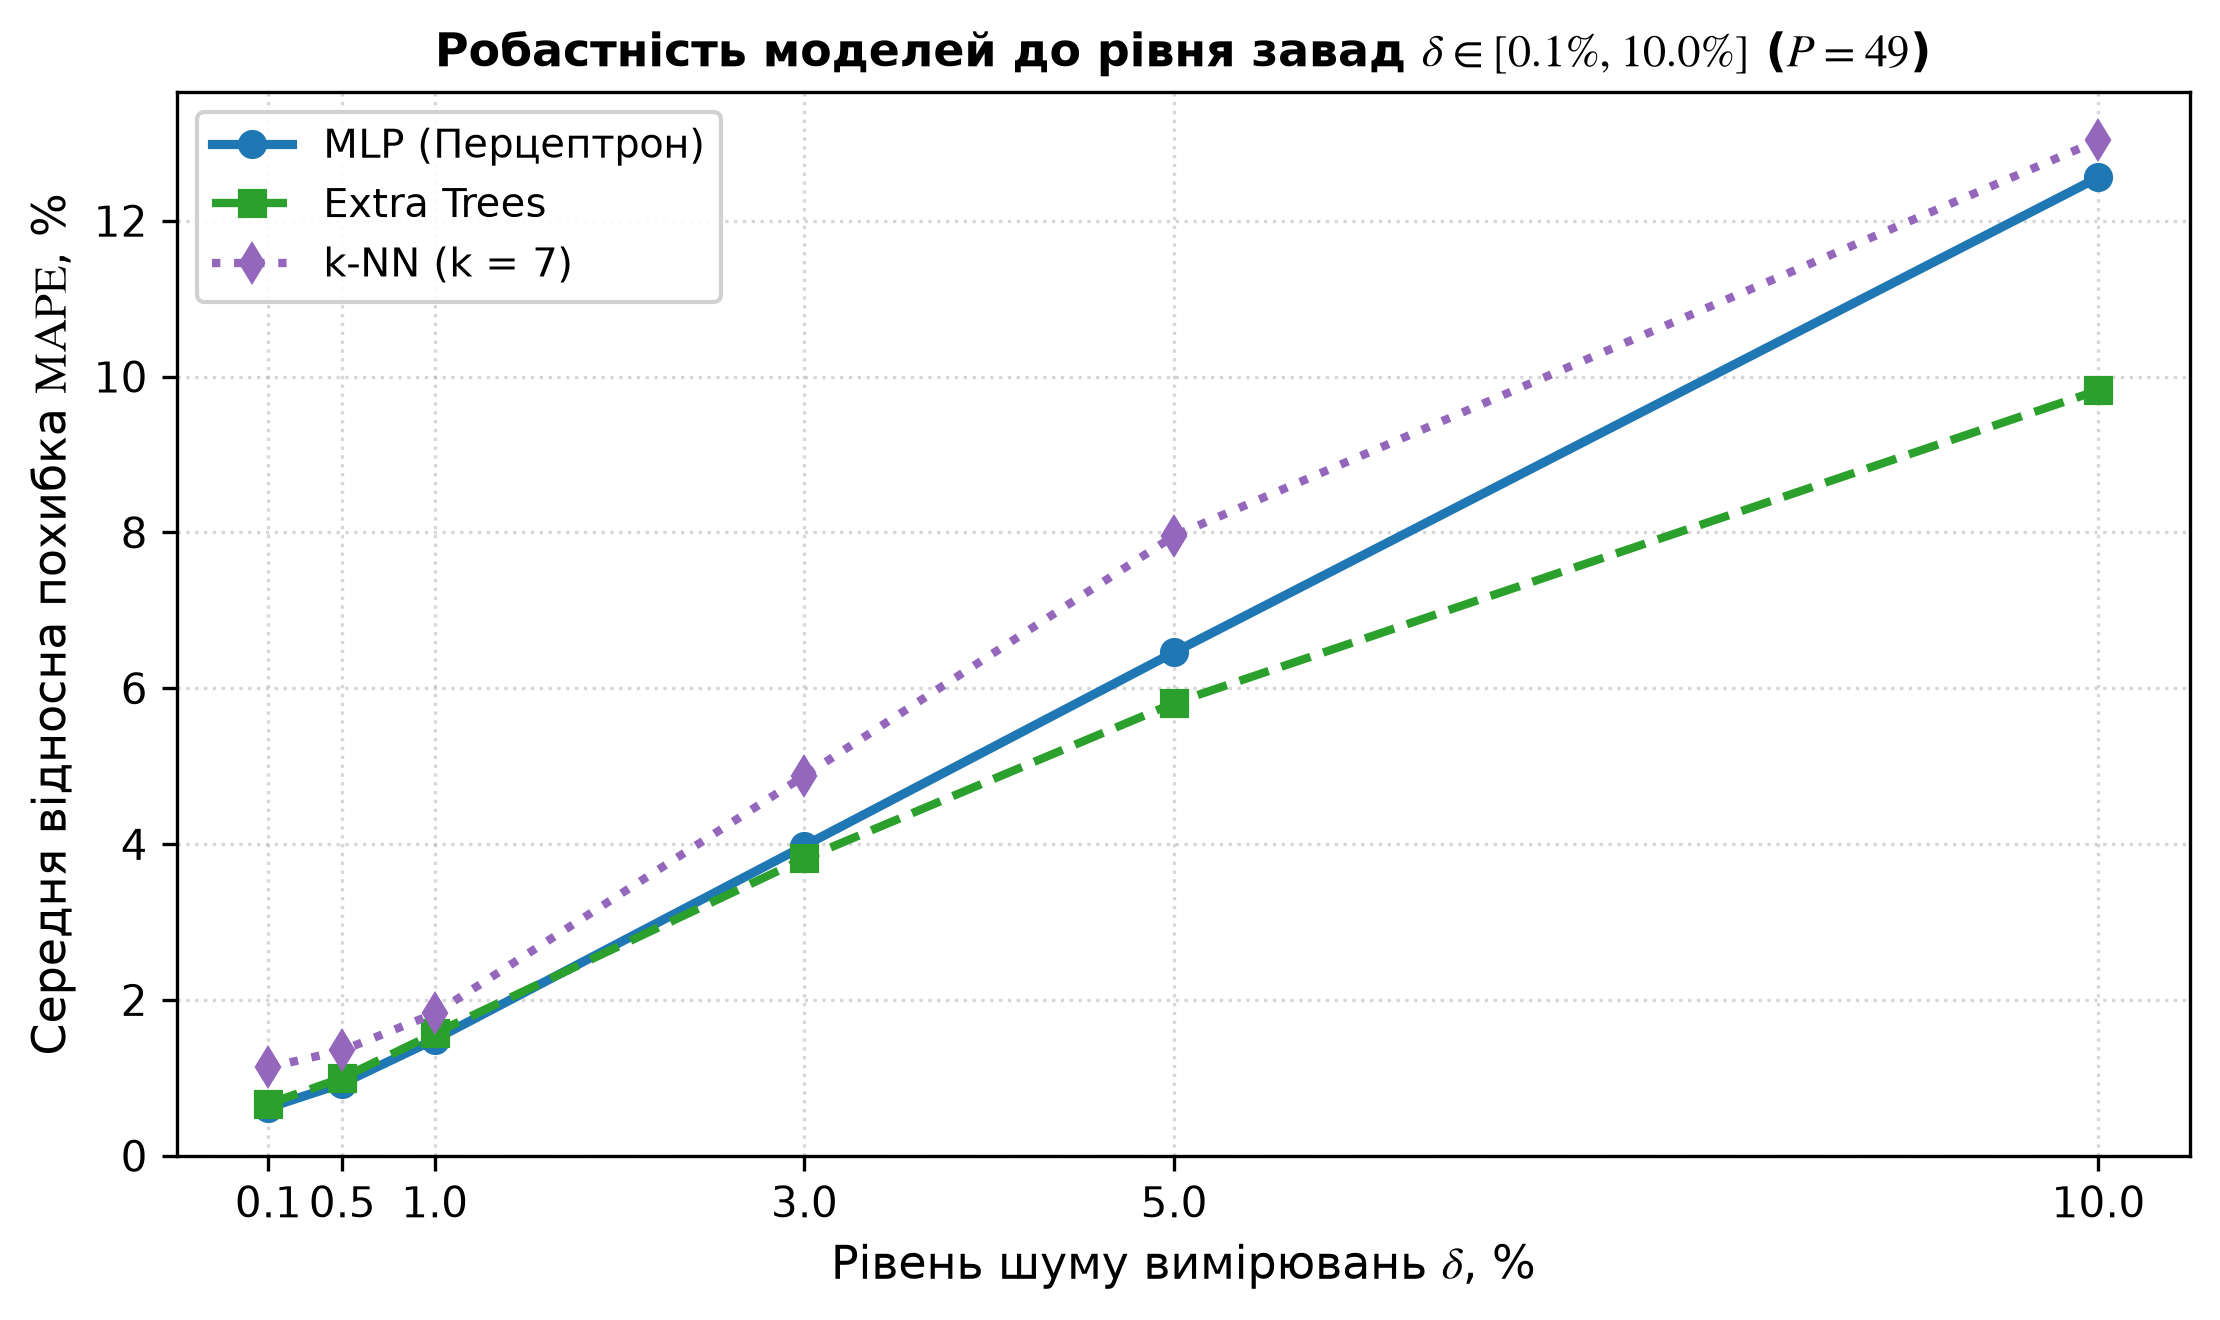

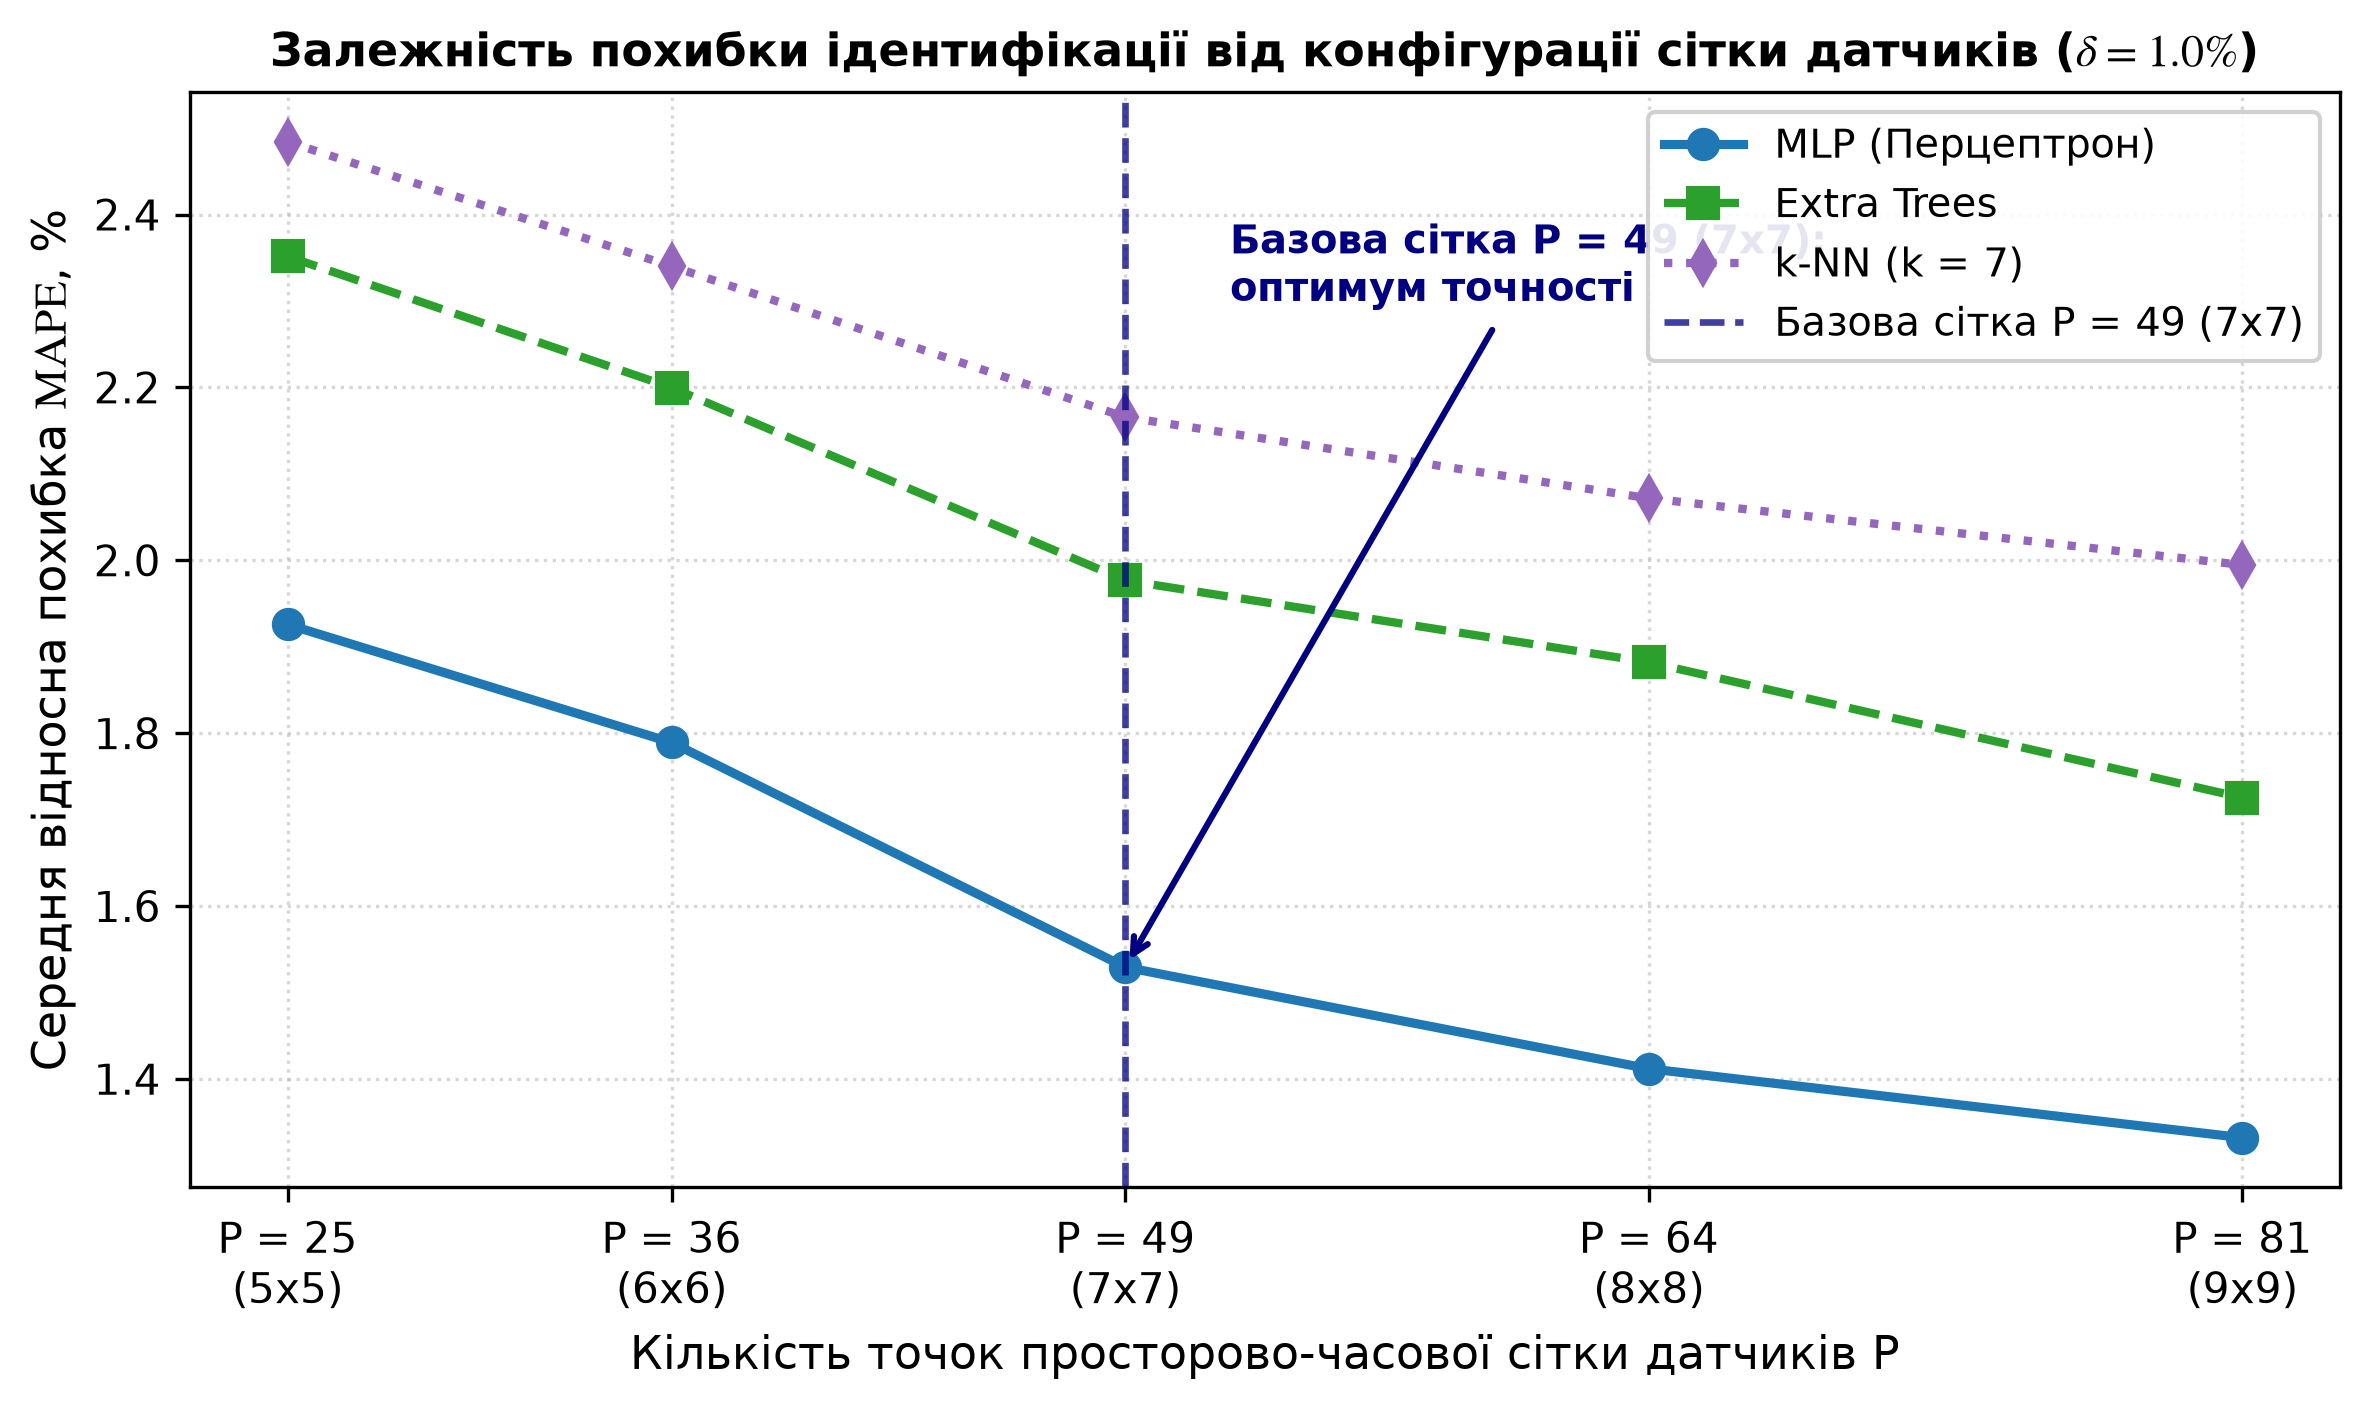

In [3]:
# Прямий розрахунок робастності до рівня шуму вимірювань delta (Таблиця 4.5)
noise_levels = [0.1, 0.5, 1.0, 3.0, 5.0, 10.0]
sub_n_te = 3000
U_cl_sub = U_clean_base[N_TRAIN:N_TRAIN + sub_n_te]
Y_te_sub = Y_te[:sub_n_te]

noise_study_num = []
TABLE_4_5 = []
for d in noise_levels:
    U_noise_d = U_cl_sub + np.random.default_rng(42).normal(0.0, (d / 100.0) * np.abs(U_cl_sub))
    Z_noise_d = (U_noise_d - mean_X) @ eigvecs[:, :4]
    Z_noise_d_s = scZ.transform(Z_noise_d)

    pred_n_mlp = scY.inverse_transform(mlp.predict(Z_noise_d_s))
    pred_n_et = et.predict(Z_noise_d)
    pred_n_knn = scY.inverse_transform(knn.predict(Z_noise_d_s))

    m_n_mlp = float(np.mean(calc_metrics(Y_te_sub, pred_n_mlp)[2]))
    m_n_et = float(np.mean(calc_metrics(Y_te_sub, pred_n_et)[2]))
    m_n_knn = float(np.mean(calc_metrics(Y_te_sub, pred_n_knn)[2]))

    noise_study_num.append((d, m_n_mlp, m_n_et, m_n_knn))
    TABLE_4_5.append([
        f"{d:.1f}%".replace(".", ","),
        f"{m_n_mlp:.2f}%".replace(".", ","),
        f"{m_n_et:.2f}%".replace(".", ","),
        f"{m_n_knn:.2f}%".replace(".", ","),
    ])

print("=" * 88)
print(" ТАБЛИЦЯ 4.5 – Залежність середньої відносної похибки MAPE (%) від рівня завад δ (P = 49, K = 4) ")
print("=" * 88)
print(f"{'Рівень шуму δ, %':^20} | {'MLP (Перцептрон)':^20} | {'Extra Trees':^20} | {'k-NN (k = 7)':^20}")
print("-" * 88)
for r in TABLE_4_5:
    print(f"{r[0]:^20} | {r[1]:^20} | {r[2]:^20} | {r[3]:^20}")
print("=" * 88)

# Прямий розрахунок впливу конфігурації сітки датчиків P (Таблиця 4.6)
grid_configs = [(5, 5), (6, 6), (7, 7), (8, 8), (9, 9)]
sub_grid_tr, sub_grid_te = 12000, 3000
p_vals_arr = [nx * nt for nx, nt in grid_configs]
grid_mlp_mapes, grid_et_mapes, grid_knn_mapes = [], [], []

for nx, nt in grid_configs:
    xs_g = np.linspace(X_MIN, X_MAX, nx)
    ts_g = np.linspace(T_MIN, T_MAX, nt)
    Xg_g, Tg_g = np.meshgrid(xs_g, ts_g)
    x_fl_g, t_fl_g = Xg_g.ravel(), Tg_g.ravel()

    U_cl_g = eval_U_field(
        Y_all[:sub_grid_tr + sub_grid_te, 0:1],
        Y_all[:sub_grid_tr + sub_grid_te, 1:2],
        Y_all[:sub_grid_tr + sub_grid_te, 2:3],
        x_fl_g, t_fl_g, K=41,
    )
    U_no_g = U_cl_g + np.random.default_rng(42).normal(0.0, 0.01 * np.abs(U_cl_g))
    X_tr_g, X_te_g = U_no_g[:sub_grid_tr], U_no_g[sub_grid_tr:]
    Y_tr_g, Y_te_g = Y_all[:sub_grid_tr], Y_all[sub_grid_tr:sub_grid_tr + sub_grid_te]

    mean_X_g = np.mean(X_tr_g, axis=0)
    e_vals_g, e_vecs_g = np.linalg.eigh(np.cov(X_tr_g - mean_X_g, rowvar=False))
    e_vecs_g = e_vecs_g[:, np.argsort(e_vals_g)[::-1]]
    Z_tr_g = (X_tr_g - mean_X_g) @ e_vecs_g[:, :4]
    Z_te_g = (X_te_g - mean_X_g) @ e_vecs_g[:, :4]

    scZ_g = StandardScaler().fit(Z_tr_g)
    scY_g = StandardScaler().fit(Y_tr_g)
    Z_tr_g_s, Z_te_g_s = scZ_g.transform(Z_tr_g), scZ_g.transform(Z_te_g)
    Y_tr_g_s = scY_g.transform(Y_tr_g)

    mlp_g = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=30, batch_size=256, random_state=42).fit(Z_tr_g_s, Y_tr_g_s)
    p_mlp_g = scY_g.inverse_transform(mlp_g.predict(Z_te_g_s))
    grid_mlp_mapes.append(float(np.mean(calc_metrics(Y_te_g, p_mlp_g)[2])))

    et_g = ExtraTreesRegressor(n_estimators=30, max_depth=12, random_state=42, n_jobs=1).fit(Z_tr_g[:6000], Y_tr_g[:6000])
    p_et_g = et_g.predict(Z_te_g)
    grid_et_mapes.append(float(np.mean(calc_metrics(Y_te_g, p_et_g)[2])))

    knn_g = KNeighborsRegressor(n_neighbors=7, n_jobs=1).fit(Z_tr_g_s[:6000], Y_tr_g_s[:6000])
    p_knn_g = scY_g.inverse_transform(knn_g.predict(Z_te_g_s))
    grid_knn_mapes.append(float(np.mean(calc_metrics(Y_te_g, p_knn_g)[2])))

TABLE_4_6 = [
    ["MLP (Перцептрон)"] + [f"{v:.2f}%".replace(".", ",") for v in grid_mlp_mapes],
    ["Extra Trees"] + [f"{v:.2f}%".replace(".", ",") for v in grid_et_mapes],
    ["k-NN (k = 7)"] + [f"{v:.2f}%".replace(".", ",") for v in grid_knn_mapes],
]

print("\n" + "=" * 98)
print(" ТАБЛИЦЯ 4.6 – Залежність середньої похибки MAPE (%) від розмірності сітки датчиків P (δ = 1,0%, K = 4) ")
print("=" * 98)
print(f"{'Модель':^22} | {'P=25 (5x5)':^12} | {'P=36 (6x6)':^12} | {'P=49 (7x7)':^12} | {'P=64 (8x8)':^12} | {'P=81 (9x9)':^12}")
print("-" * 98)
for r in TABLE_4_6:
    print(f"{r[0]:<22} | {r[1]:^12} | {r[2]:^12} | {r[3]:^12} | {r[4]:^12} | {r[5]:^12}")
print("=" * 98)

# Рисунок 4.6: Робастність моделей до рівня завад
fig4_6, ax = plt.subplots(figsize=(7.5, 4.5), dpi=150)
ax.plot(noise_levels, [r[1] for r in noise_study_num], "o-", lw=2.2, color="#1f77b4", label="MLP (Перцептрон)")
ax.plot(noise_levels, [r[2] for r in noise_study_num], "s--", lw=2.0, color="#2ca02c", label="Extra Trees")
ax.plot(noise_levels, [r[3] for r in noise_study_num], "d:", lw=2.0, color="#9467bd", label="k-NN (k = 7)")
ax.set_xlabel(r"Рівень шуму вимірювань $\delta$, %", fontsize=11)
ax.set_ylabel(r"Середня відносна похибка $\mathrm{MAPE}$, %", fontsize=11)
ax.set_title(r"Робастність моделей до рівня завад $\delta \in [0.1\%, 10.0\%]$ ($P = 49$)", fontsize=11, fontweight="bold")
ax.set_xticks(noise_levels)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(fontsize=9.5)
plt.tight_layout()
plt.show()

# Рисунок 4.7: Вплив кількості датчиків та конфігурації сітки P
fig4_7, ax = plt.subplots(figsize=(8.0, 4.8), dpi=150)
ax.plot(p_vals_arr, grid_mlp_mapes, "o-", lw=2.2, color="#1f77b4", ms=7, label="MLP (Перцептрон)")
ax.plot(p_vals_arr, grid_et_mapes, "s--", lw=2.0, color="#2ca02c", ms=7, label="Extra Trees")
ax.plot(p_vals_arr, grid_knn_mapes, "d:", lw=2.0, color="#9467bd", ms=7, label="k-NN (k = 7)")
ax.axvline(49, color="navy", ls="--", lw=1.6, alpha=0.75, label="Базова сітка P = 49 (7x7)")
ax.annotate("Базова сітка P = 49 (7x7):\nоптимум точності", xy=(49, grid_mlp_mapes[2]), xytext=(52, 2.3),
            arrowprops=dict(arrowstyle="->", lw=1.5, color="navy"), fontsize=9.5, fontweight="bold", color="navy")
ax.set_xticks(p_vals_arr)
ax.set_xticklabels(["P = 25\n(5x5)", "P = 36\n(6x6)", "P = 49\n(7x7)", "P = 64\n(8x8)", "P = 81\n(9x9)"], fontsize=10)
ax.set_xlabel("Кількість точок просторово-часової сітки датчиків P", fontsize=11)
ax.set_ylabel(r"Середня відносна похибка $\mathrm{MAPE}$, %", fontsize=11)
ax.set_title(r"Залежність похибки ідентифікації від конфігурації сітки датчиків ($\delta = 1.0\%$)", fontsize=11, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper right", fontsize=9.5)
plt.tight_layout()
plt.show()

## 4.6–4.7. Двоетапна каскадна схема `Cascade MLP` та верифікація у широкому діапазоні швидкостей $a \in [1{,}0;\; 30{,}0]$ м/с (**Таблиці 4.7, 4.8**, **Рисунки 4.8, 4.9**)

 ТАБЛИЦЯ 4.7 – Ефективність двоетапної (каскадної) схеми ідентифікації порівняно з базовим MLP (P = 49) 
Параметр струни            |   Діапазон   |  Базовий MLP   |  Cascade MLP   |  R^2 (Каскад)  | Відносне покращення 
----------------------------------------------------------------------------------------------------------------
Фазова швидкість a, м/с    |  [1,0; 3,2]  |     3,78%      |     2,96%      |     0,9883     |        +21,7%       
Робоча довжина l, м        |  [0,8; 1,2]  |     0,25%      |     0,22%      |     0,9994     |        +12,4%       
Початковий відгин A, м^-1  |  [0,8; 1,2]  |     0,47%      |     0,42%      |     0,9978     |  Етап 1 (збережено) 
Середня MAPE, %            |      –       |     1,50%      |     1,20%      |       –        |        +19,9%       

 ТАБЛИЦЯ 4.8 – Порівняння точності моделей у широкому діапазоні швидкостей a in [1,0; 30,0] м/с (P = 49, δ = 1,0%) 
Модель машинного навчання          |  MAPE a   |  MAPE l   |  MAPE A   | Сер. MAPE  |

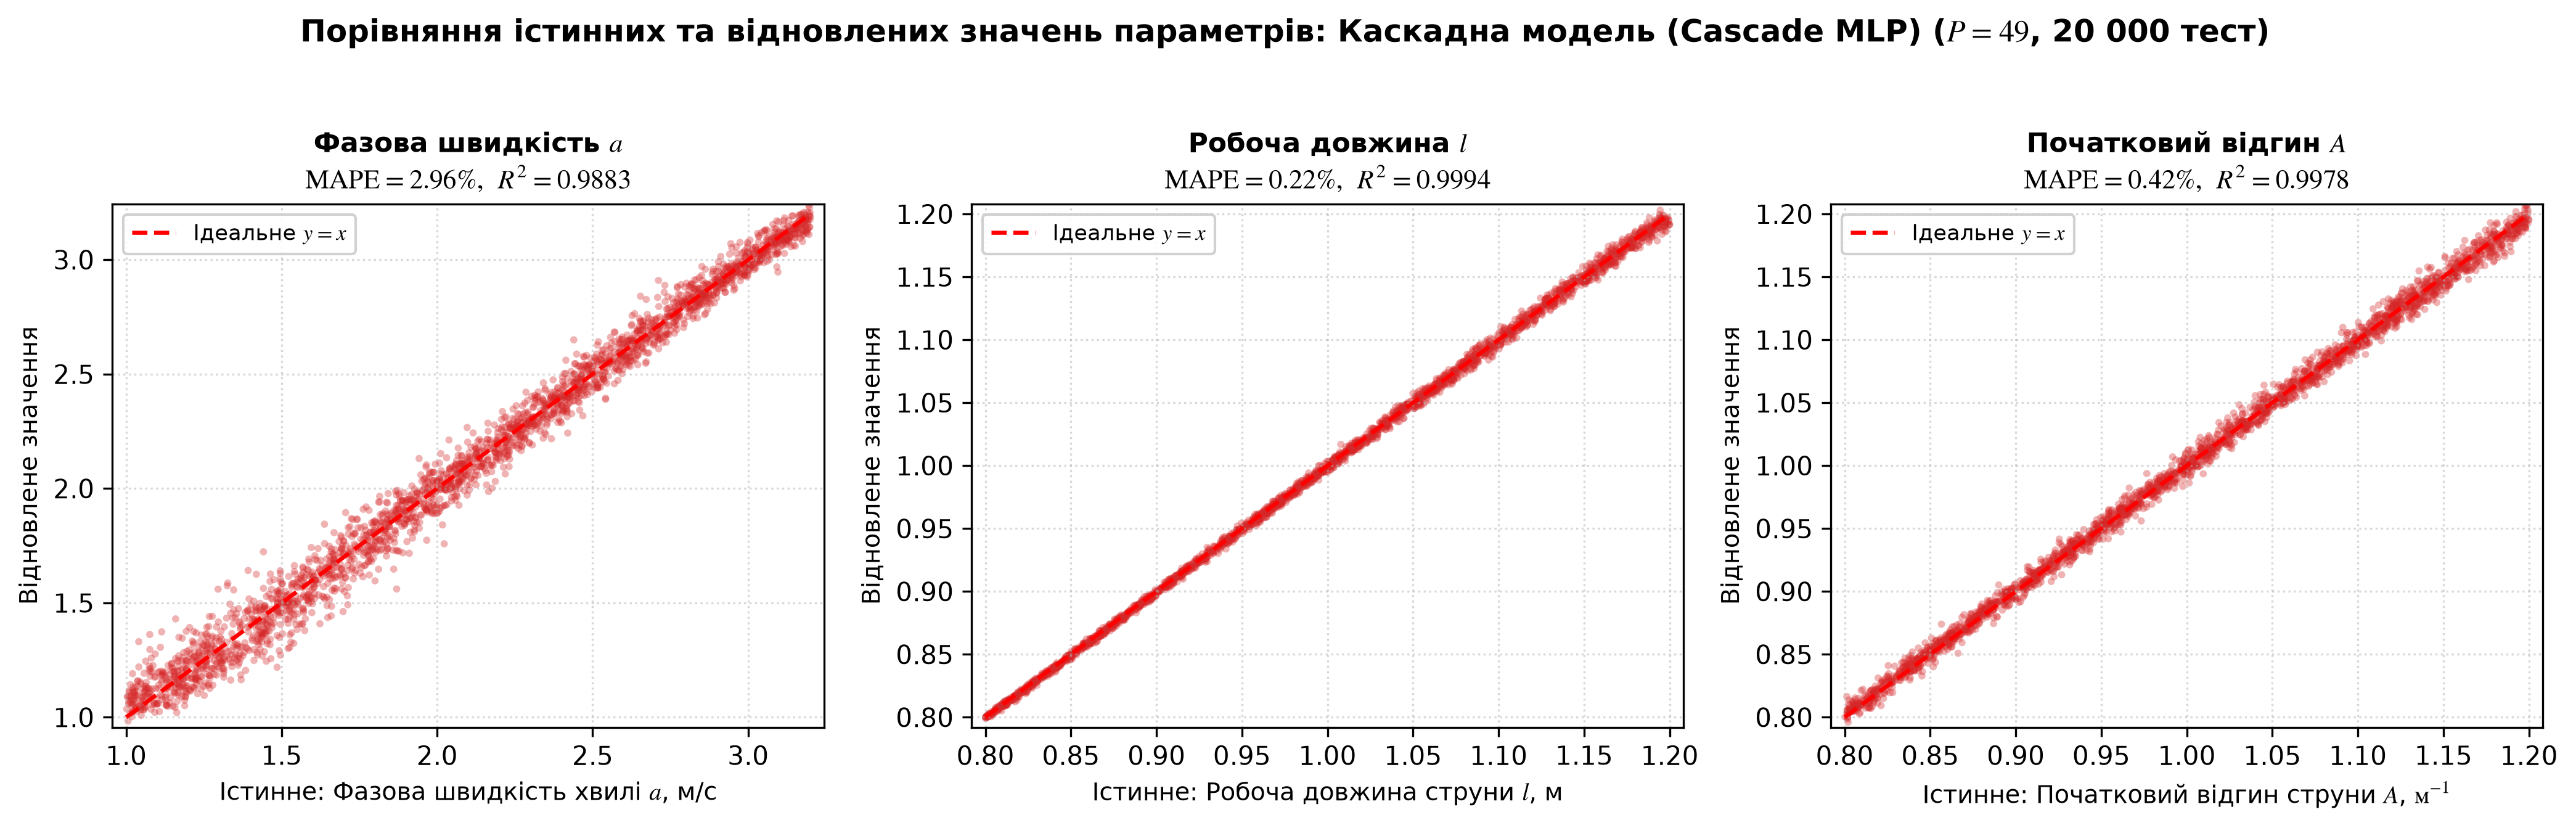

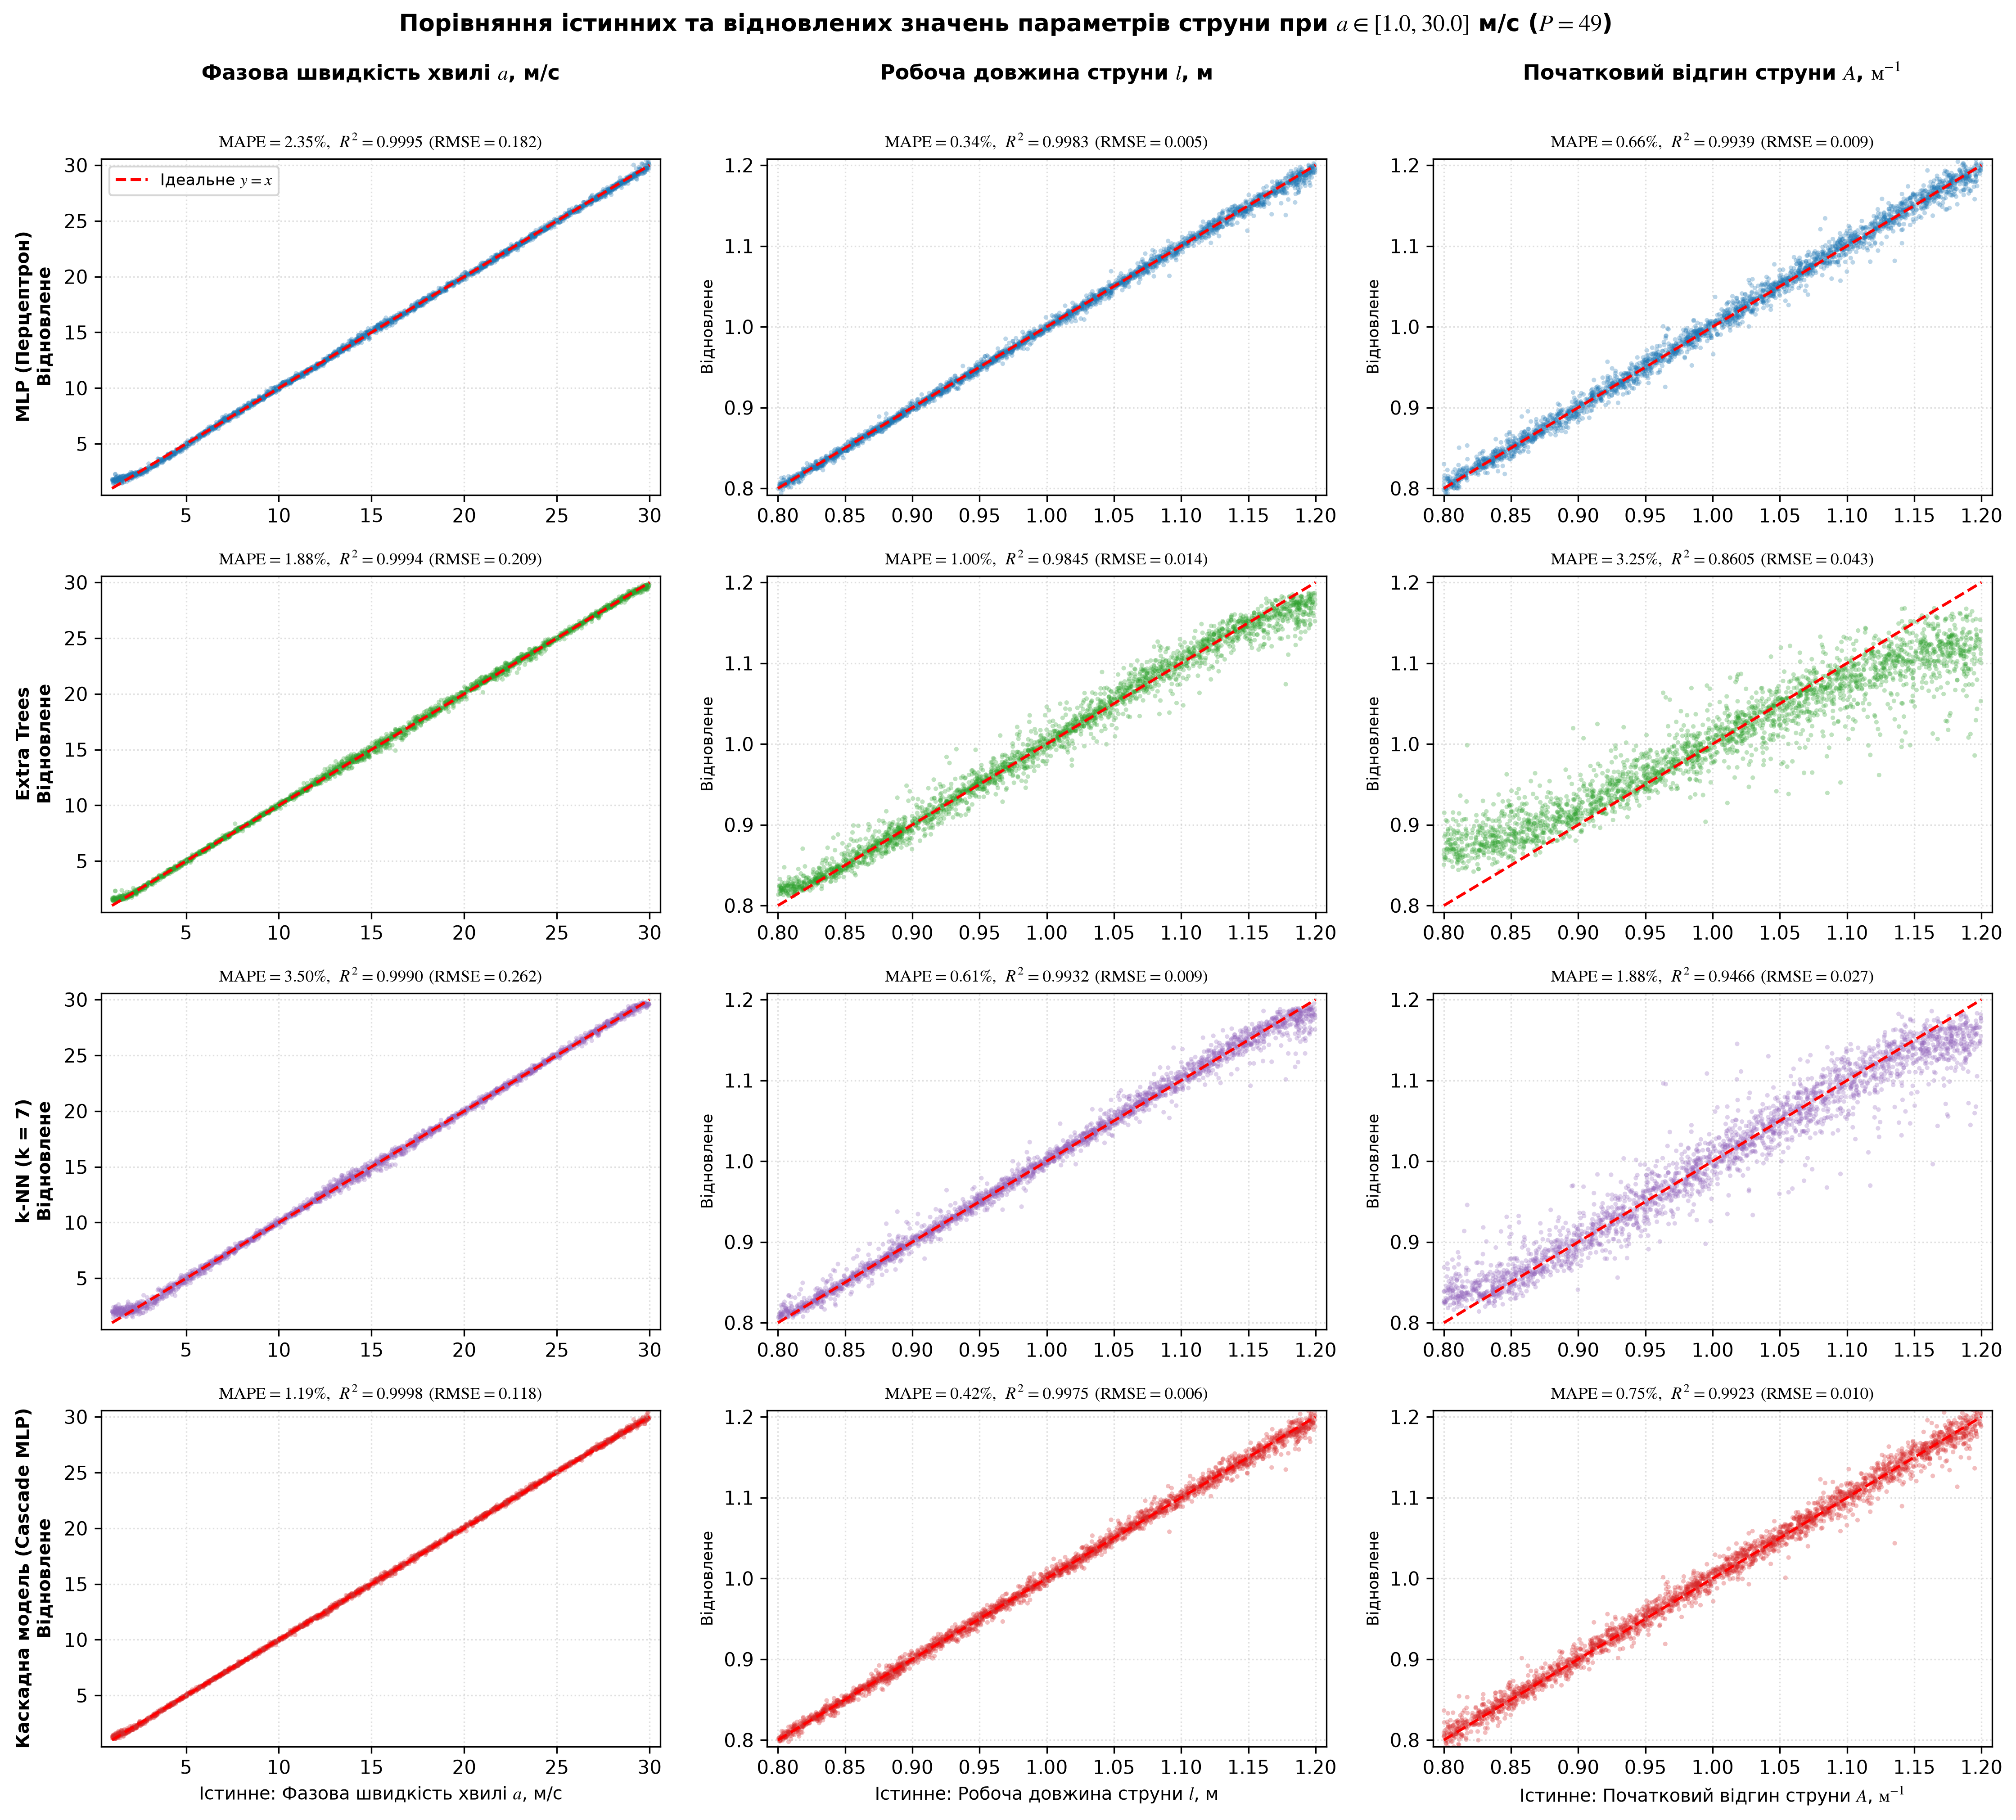

In [4]:
# 1. Двоетапна (каскадна) схема Cascade MLP (Таблиця 4.7, Рисунок 4.8)
scY_geom = StandardScaler().fit(Y_tr[:, [1, 2]])
mlp_s1 = MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", max_iter=40, batch_size=512, learning_rate_init=0.003, random_state=42)
mlp_s1.fit(Z_tr_s, scY_geom.transform(Y_tr[:, [1, 2]]))
pred_tr_geom = scY_geom.inverse_transform(mlp_s1.predict(Z_tr_s))
pred_te_geom = scY_geom.inverse_transform(mlp_s1.predict(Z_te_s))

base_tr = (8.0 * pred_tr_geom[:, 1:2] * (pred_tr_geom[:, 0:1] ** 2) / (np.pi ** 3)) * np.sin(np.pi * X_FLAT_BASE[None, :] / pred_tr_geom[:, 0:1])
phase_tr = np.clip(X_tr / np.where(np.abs(base_tr) < 1e-4, 1e-4, base_tr), -1.2, 1.2)

base_te = (8.0 * pred_te_geom[:, 1:2] * (pred_te_geom[:, 0:1] ** 2) / (np.pi ** 3)) * np.sin(np.pi * X_FLAT_BASE[None, :] / pred_te_geom[:, 0:1])
phase_te = np.clip(X_te / np.where(np.abs(base_te) < 1e-4, 1e-4, base_te), -1.2, 1.2)

feat_tr = np.column_stack([Z_tr, pred_tr_geom, phase_tr])
feat_te = np.column_stack([Z_te, pred_te_geom, phase_te])

scF = StandardScaler().fit(feat_tr)
sc_a = StandardScaler().fit(Y_tr[:, 0:1])
mlp_s2 = MLPRegressor(hidden_layer_sizes=(128, 64, 32), activation="relu", max_iter=45, batch_size=512, learning_rate_init=0.003, random_state=42)
mlp_s2.fit(scF.transform(feat_tr), sc_a.transform(Y_tr[:, 0:1]).ravel())
pred_a_s2 = sc_a.inverse_transform(mlp_s2.predict(scF.transform(feat_te)).reshape(-1, 1)).flatten()

pred_casc = np.column_stack([pred_a_s2, pred_te_geom[:, 0], pred_te_geom[:, 1]])
m_casc = calc_metrics(Y_te, pred_casc)

impr_a = (m_mlp[2][0] - m_casc[2][0]) / m_mlp[2][0] * 100.0
impr_l = (m_mlp[2][1] - m_casc[2][1]) / m_mlp[2][1] * 100.0
impr_mean = (np.mean(m_mlp[2]) - np.mean(m_casc[2])) / np.mean(m_mlp[2]) * 100.0

TABLE_4_7 = [
    ["Фазова швидкість a, м/с", "[1,0; 3,2]", f"{m_mlp[2][0]:.2f}%".replace(".", ","), f"{m_casc[2][0]:.2f}%".replace(".", ","), f"{m_casc[3][0]:.4f}".replace(".", ","), f"{impr_a:+.1f}%".replace(".", ",")],
    ["Робоча довжина l, м", "[0,8; 1,2]", f"{m_mlp[2][1]:.2f}%".replace(".", ","), f"{m_casc[2][1]:.2f}%".replace(".", ","), f"{m_casc[3][1]:.4f}".replace(".", ","), f"{impr_l:+.1f}%".replace(".", ",") if abs(impr_l) >= 1.0 else "Етап 1 (збережено)"],
    ["Початковий відгин A, м^-1", "[0,8; 1,2]", f"{m_mlp[2][2]:.2f}%".replace(".", ","), f"{m_casc[2][2]:.2f}%".replace(".", ","), f"{m_casc[3][2]:.4f}".replace(".", ","), "Етап 1 (збережено)"],
    ["Середня MAPE, %", "–", f"{np.mean(m_mlp[2]):.2f}%".replace(".", ","), f"{np.mean(m_casc[2]):.2f}%".replace(".", ","), "–", f"{impr_mean:+.1f}%".replace(".", ",")],
]

print("=" * 112)
print(" ТАБЛИЦЯ 4.7 – Ефективність двоетапної (каскадної) схеми ідентифікації порівняно з базовим MLP (P = 49) ")
print("=" * 112)
print(f"{'Параметр струни':<26} | {'Діапазон':^12} | {'Базовий MLP':^14} | {'Cascade MLP':^14} | {'R^2 (Каскад)':^14} | {'Відносне покращення':^20}")
print("-" * 112)
for r in TABLE_4_7:
    print(f"{r[0]:<26} | {r[1]:^12} | {r[2]:^14} | {r[3]:^14} | {r[4]:^14} | {r[5]:^20}")
print("=" * 112)

# Рисунок 4.8: Діаграма розсіювання для Cascade MLP
plot_model_scatter_3panel("Каскадна модель (Cascade MLP)", Y_te, pred_casc, "#d62728")

# 2. Розширений діапазон швидкостей a in [1,0; 30,0] м/с (Таблиця 4.8, Рисунок 4.9)
bounds_30 = np.array([[1.0, 30.0], [0.8, 1.2], [0.8, 1.2]], dtype=np.float64)
Y_30_c = lhs_sample(20000, bounds_30, seed=42)
U_30_c = eval_U_field(Y_30_c[:, 0:1], Y_30_c[:, 1:2], Y_30_c[:, 2:3], X_FLAT_BASE, T_FLAT_BASE, K=25)
U_30_n = U_30_c + np.random.default_rng(42).normal(0.0, 0.01 * np.abs(U_30_c))
X_tr30, X_te30 = U_30_n[:16000], U_30_n[16000:]
Y_tr30, Y_te30 = Y_30_c[:16000], Y_30_c[16000:]

mu30 = np.mean(X_tr30, axis=0)
ev30, evec30 = np.linalg.eigh(np.cov(X_tr30 - mu30, rowvar=False))
evec30 = evec30[:, np.argsort(ev30)[::-1]]
Z_tr30, Z_te30 = (X_tr30 - mu30) @ evec30[:, :4], (X_te30 - mu30) @ evec30[:, :4]
scZ30, scY30 = StandardScaler().fit(Z_tr30), StandardScaler().fit(Y_tr30)
Z_tr30_s, Z_te30_s = scZ30.transform(Z_tr30), scZ30.transform(Z_te30)
Y_tr30_s = scY30.transform(Y_tr30)

p_mlp30 = scY30.inverse_transform(MLPRegressor(hidden_layer_sizes=(128, 64, 32), max_iter=60, batch_size=256, random_state=42).fit(Z_tr30_s, Y_tr30_s).predict(Z_te30_s))
p_et30 = ExtraTreesRegressor(n_estimators=40, max_depth=16, min_samples_leaf=4, random_state=42, n_jobs=1).fit(Z_tr30[:10000], Y_tr30[:10000]).predict(Z_te30)
p_knn30 = scY30.inverse_transform(KNeighborsRegressor(n_neighbors=7, n_jobs=1).fit(Z_tr30_s[:10000], Y_tr30_s[:10000]).predict(Z_te30_s))

scY30_geom = StandardScaler().fit(Y_tr30[:, [1, 2]])
mlp30_s1 = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=50, batch_size=256, random_state=42).fit(Z_tr30_s, scY30_geom.transform(Y_tr30[:, [1, 2]]))
pred_te30_geom = scY30_geom.inverse_transform(mlp30_s1.predict(Z_te30_s))

base_tr30 = (8.0 * Y_tr30[:, 2:3] * (Y_tr30[:, 1:2] ** 2) / (np.pi ** 3)) * np.sin(np.pi * X_FLAT_BASE[None, :] / Y_tr30[:, 1:2])
base_te30 = (8.0 * pred_te30_geom[:, 1:2] * (pred_te30_geom[:, 0:1] ** 2) / (np.pi ** 3)) * np.sin(np.pi * X_FLAT_BASE[None, :] / pred_te30_geom[:, 0:1])
phase_tr30 = np.clip(X_tr30 / np.where(np.abs(base_tr30) < 1e-4, 1e-4, base_tr30), -1.2, 1.2)
phase_te30 = np.clip(X_te30 / np.where(np.abs(base_te30) < 1e-4, 1e-4, base_te30), -1.2, 1.2)

feat_tr30 = np.column_stack([Z_tr30, Y_tr30[:, [1, 2]], phase_tr30])
feat_te30 = np.column_stack([Z_te30, pred_te30_geom, phase_te30])
scF30 = StandardScaler().fit(feat_tr30)
sc_a30 = StandardScaler().fit(Y_tr30[:, 0:1])
mlp30_s2 = MLPRegressor(hidden_layer_sizes=(128, 64, 32), max_iter=60, batch_size=256, random_state=42).fit(scF30.transform(feat_tr30), sc_a30.transform(Y_tr30[:, 0:1]).ravel())
pred_a30_s2 = sc_a30.inverse_transform(mlp30_s2.predict(scF30.transform(feat_te30)).reshape(-1, 1)).flatten()
p_casc30 = np.column_stack([pred_a30_s2, pred_te30_geom[:, 0], pred_te30_geom[:, 1]])

m_mlp30 = calc_metrics(Y_te30, p_mlp30)
m_et30 = calc_metrics(Y_te30, p_et30)
m_knn30 = calc_metrics(Y_te30, p_knn30)
m_casc30 = calc_metrics(Y_te30, p_casc30)

TABLE_4_8 = []
for m_label, m_res30 in [
    ("Каскадна модель (Cascade MLP)", m_casc30),
    ("MLP (Багатошаровий перцептрон)", m_mlp30),
    ("k-NN (k = 7 сусідів)", m_knn30),
    ("Extra Trees (Екстремальні дерева)", m_et30),
]:
    mae30, rmse30, mape30, r2_30 = m_res30
    TABLE_4_8.append([
        m_label,
        f"{mape30[0]:.2f}%".replace(".", ","),
        f"{mape30[1]:.2f}%".replace(".", ","),
        f"{mape30[2]:.2f}%".replace(".", ","),
        f"{np.mean(mape30):.2f}%".replace(".", ","),
        f"{np.mean(r2_30):.4f}".replace(".", ","),
        f"{rmse30[0]:.3f}".replace(".", ","),
    ])

print("\n" + "=" * 112)
print(" ТАБЛИЦЯ 4.8 – Порівняння точності моделей у широкому діапазоні швидкостей a in [1,0; 30,0] м/с (P = 49, δ = 1,0%) ")
print("=" * 112)
print(f"{'Модель машинного навчання':<34} | {'MAPE a':^9} | {'MAPE l':^9} | {'MAPE A':^9} | {'Сер. MAPE':^10} | {'Сер. R^2':^10} | {'RMSE a, м/с':^12}")
print("-" * 112)
for r in TABLE_4_8:
    print(f"{r[0]:<34} | {r[1]:^9} | {r[2]:^9} | {r[3]:^9} | {r[4]:^10} | {r[5]:^10} | {r[6]:^12}")
print("=" * 112)

fig4_9, axes = plt.subplots(4, 3, figsize=(15.0, 13.5), dpi=150)
for i, (m_title, Y_pred, color) in enumerate([
    ("MLP (Перцептрон)", p_mlp30, "#1f77b4"),
    ("Extra Trees", p_et30, "#2ca02c"),
    ("k-NN (k = 7)", p_knn30, "#9467bd"),
    ("Каскадна модель (Cascade MLP)", p_casc30, "#d62728"),
]):
    for j in range(3):
        ax = axes[i, j]
        ax.scatter(Y_te30[:, j], Y_pred[:, j], alpha=0.30, s=6, color=color, edgecolors="none")
        b_min, b_max = bounds_30[j]
        ax.plot([b_min, b_max], [b_min, b_max], "r--", lw=1.5)
        if i == 3:
            ax.set_xlabel(f"Істинне: {p_names[j]}", fontsize=9.5)
        ax.set_ylabel(f"{m_title}\nВідновлене" if j == 0 else "Відновлене", fontsize=9.0)
        ax.grid(True, linestyle=":", alpha=0.4)
fig4_9.suptitle(r"Порівняння істинних та відновлених значень параметрів струни при $a \in [1.0, 30.0]$ м/с ($P = 49$)", fontsize=12.5, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

## Експорт синтетичного датасету (20 000 тестових прикладів із координатами $Z_1 \dots Z_4$) та усіх таблиць диплому в Microsoft Excel (`.xlsx`)

In [5]:
# Формування таблиці 20 000 тестових прикладів із латентними координатами ГК Z1..Z4 та прогнозами 4 моделей
df_test_20k_export = pd.DataFrame({
    "№ зразка": np.arange(1, N_TEST + 1),
    "a істинне, м/с": np.round(Y_te[:, 0], 5),
    "l істинне, м": np.round(Y_te[:, 1], 5),
    "A істинне, м^-1": np.round(Y_te[:, 2], 5),
    "ГК Z1": np.round(Z_te[:, 0], 6),
    "ГК Z2": np.round(Z_te[:, 1], 6),
    "ГК Z3": np.round(Z_te[:, 2], 6),
    "ГК Z4": np.round(Z_te[:, 3], 6),
    "MLP: a прогноз": np.round(pred_mlp[:, 0], 5),
    "MLP: l прогноз": np.round(pred_mlp[:, 1], 5),
    "MLP: A прогноз": np.round(pred_mlp[:, 2], 5),
    "ExtraTrees: a прогноз": np.round(pred_et[:, 0], 5),
    "ExtraTrees: l прогноз": np.round(pred_et[:, 1], 5),
    "ExtraTrees: A прогноз": np.round(pred_et[:, 2], 5),
    "k-NN: a прогноз": np.round(pred_knn[:, 0], 5),
    "k-NN: l прогноз": np.round(pred_knn[:, 1], 5),
    "k-NN: A прогноз": np.round(pred_knn[:, 2], 5),
    "CascadeMLP: a прогноз": np.round(pred_casc[:, 0], 5),
    "CascadeMLP: l прогноз": np.round(pred_casc[:, 1], 5),
    "CascadeMLP: A прогноз": np.round(pred_casc[:, 2], 5),
})

excel_out_name = "Результати_PCA_Магістерська_Єфіменко.xlsx"
with pd.ExcelWriter(excel_out_name, engine="openpyxl") as writer:
    pd.DataFrame(TABLE_4_1, columns=["ГК", "Власне значення", "Частка дисперсії", "Кумулятивна частка", "Фізичний зміст"]).to_excel(writer, sheet_name="Таблиця_4_1_Спектр_PCA", index=False)
    pd.DataFrame(TABLE_4_2, columns=["K", "Дисперсія", "Втрата енергії", "MAPE_a", "MAPE_l", "MAPE_A", "MAPE_mean", "R2_mean", "Стиснення"]).to_excel(writer, sheet_name="Таблиця_4_2_Вибір_K", index=False)
    pd.DataFrame(TABLE_4_3, columns=["Модель", "Параметр", "MAE", "RMSE", "MAPE", "R2", "MAPE_моделі"]).to_excel(writer, sheet_name="Таблиця_4_3_Точність_ML", index=False)
    pd.DataFrame(TABLE_4_4, columns=["Модель", "Час_навчання", "Час_прогнозу_1_профілю", "MAPE", "Рекомендований_режим"]).to_excel(writer, sheet_name="Таблиця_4_4_Швидкодія", index=False)
    pd.DataFrame(TABLE_4_5, columns=["Шум_delta_%", "MLP_MAPE_%", "ExtraTrees_MAPE_%", "kNN_MAPE_%"]).to_excel(writer, sheet_name="Таблиця_4_5_Робастність", index=False)
    pd.DataFrame(TABLE_4_6, columns=["Модель", "P25_5x5", "P36_6x6", "P49_7x7", "P64_8x8", "P81_9x9"]).to_excel(writer, sheet_name="Таблиця_4_6_Сітка_датчиків", index=False)
    pd.DataFrame(TABLE_4_7, columns=["Параметр", "Діапазон", "MLP_MAPE", "Cascade_MAPE", "R2_Cascade", "Покращення"]).to_excel(writer, sheet_name="Таблиця_4_7_Cascade_MLP", index=False)
    pd.DataFrame(TABLE_4_8, columns=["Модель", "MAPE_a", "MAPE_l", "MAPE_A", "MAPE_mean", "R2_mean", "RMSE_a"]).to_excel(writer, sheet_name="Таблиця_4_8_Діапазон_1_30", index=False)
    df_test_20k_export.to_excel(writer, sheet_name="Тестові приклади PCA (20000)", index=False)

print(f"Збережено Excel-файл із обчисленими таблицями та 20 000 тестовими прикладами: {excel_out_name}")
print(df_test_20k_export[["№ зразка", "a істинне, м/с", "l істинне, м", "A істинне, м^-1", "ГК Z1", "ГК Z2", "ГК Z3", "ГК Z4"]].head(5).to_string(index=False))

Збережено Excel-файл із обчисленими таблицями та 20 000 тестовими прикладами: Результати_PCA_Магістерська_Єфіменко.xlsx
 № зразка  a істинне, м/с  l істинне, м  A істинне, м^-1     ГК Z1     ГК Z2     ГК Z3    ГК Z4
        1         1.93066       1.12948          0.82866  0.106750  0.077112  0.008092 0.001456
        2         2.84732       0.80737          0.85513 -0.732493  0.032458 -0.011828 0.001101
        3         2.96274       1.01511          1.14355  0.218372 -0.038833 -0.028572 0.002662
        4         1.18312       0.81544          1.01653 -0.539237 -0.043980  0.020171 0.000016
        5         2.80375       1.13123          0.86841  0.154752  0.073360 -0.016076 0.004500
